# Domain: House Price Prediction

## Context of Dataset:

Dataset Description and Link:
Ask a home buyer to describe their dream house, and they probably won't begin with the height of the basement ceiling or the proximity to an east-west railroad. But this playground competition's dataset proves that much more influences price negotiations than the number of bedrooms or a white-picket fence.

With 79 explanatory variables describing (almost) every aspect of residential homes in Ames, Iowa, this competition challenges you to predict the final price of each home.

Practice Skills

●	Creative feature engineering 

●	Advanced regression techniques like random forest and gradient boosting


In [3]:
# Importing required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost not installed — will only run RandomForest. `pip install xgboost` to enable it.")

RANDOM_STATE = 42

In [4]:
# 1. Load the RAW dataset
# ------------------------------------------------------------------
CSV_PATH = '/Users/anmolgupta/Desktop/Datamites Internship/House_price_prediction (PRCP-1020)/data.csv'         # path to your raw file
TARGET = "SalePrice"                        # Target Column

df = pd.read_csv(CSV_PATH)
print(f"Raw data shape: {df.shape}")
pd.set_option('display.max_columns', None)

Raw data shape: (1460, 81)


### Initial Basic Checks

In [6]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [8]:
# Show only columns with missing values

null_counts = df.isnull().sum()
null_counts = null_counts[null_counts > 0]

print(null_counts)

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64


In [9]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1900.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,223.000000,795.750000,882.000000,0.000000,0.000000,1129.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1961.000000,1.000000,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,477.500000,991.500000,1087.000000,0.000000,0.000000,1464.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1980.000000,2.000000,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,808.000000,1298.250000,1391.250000,728.000000,0.000000,1776.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,2336.000000,6110.000000,4692.000000,2065.000000,572.000000,5642.000000,3.000000,2.000000,3.000000,2.000000,8.000000,3.000000,14.000000,3.000000,2010.000000,4.000000,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [10]:
df.describe(include='O')

,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,Heating,HeatingQC,CentralAir,Electrical,KitchenQual,Functional,FireplaceQu,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
count,1460,1460,91,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,588,1460,1460,1460,1423,1423,1422,1423,1422,1460,1460,1460,1459,1460,1460,770,1379,1379,1379,1379,1460,7,281,54,1460,1460
unique,5,2,2,4,4,2,5,3,25,9,8,5,8,6,8,15,16,3,4,5,6,4,4,4,6,6,6,5,2,5,4,7,5,6,3,5,5,3,3,4,4,9,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,Gable,CompShg,VinylSd,VinylSd,BrkFace,TA,TA,PConc,TA,TA,No,Unf,Unf,GasA,Ex,Y,SBrkr,TA,Typ,Gd,Attchd,Unf,TA,TA,Y,Gd,MnPrv,Shed,WD,Normal
freq,1151,1454,50,925,1311,1459,1052,1382,225,1260,1445,1220,726,1141,1434,515,504,445,906,1282,647,649,1311,953,430,1256,1428,741,1365,1334,735,1360,380,870,605,1311,1326,1340,3,157,49,1267,1198


## Task 1: Data Analysis Report on given data.
## EDA - Explorartory Data Analysis

### 1. Univariant Analysis

In [13]:
# Selecting only numerical value columns in the num_col variable

num_col = df.select_dtypes(include=["int64",'float64']).columns

#### a. Plotting Histogram for numerical columns

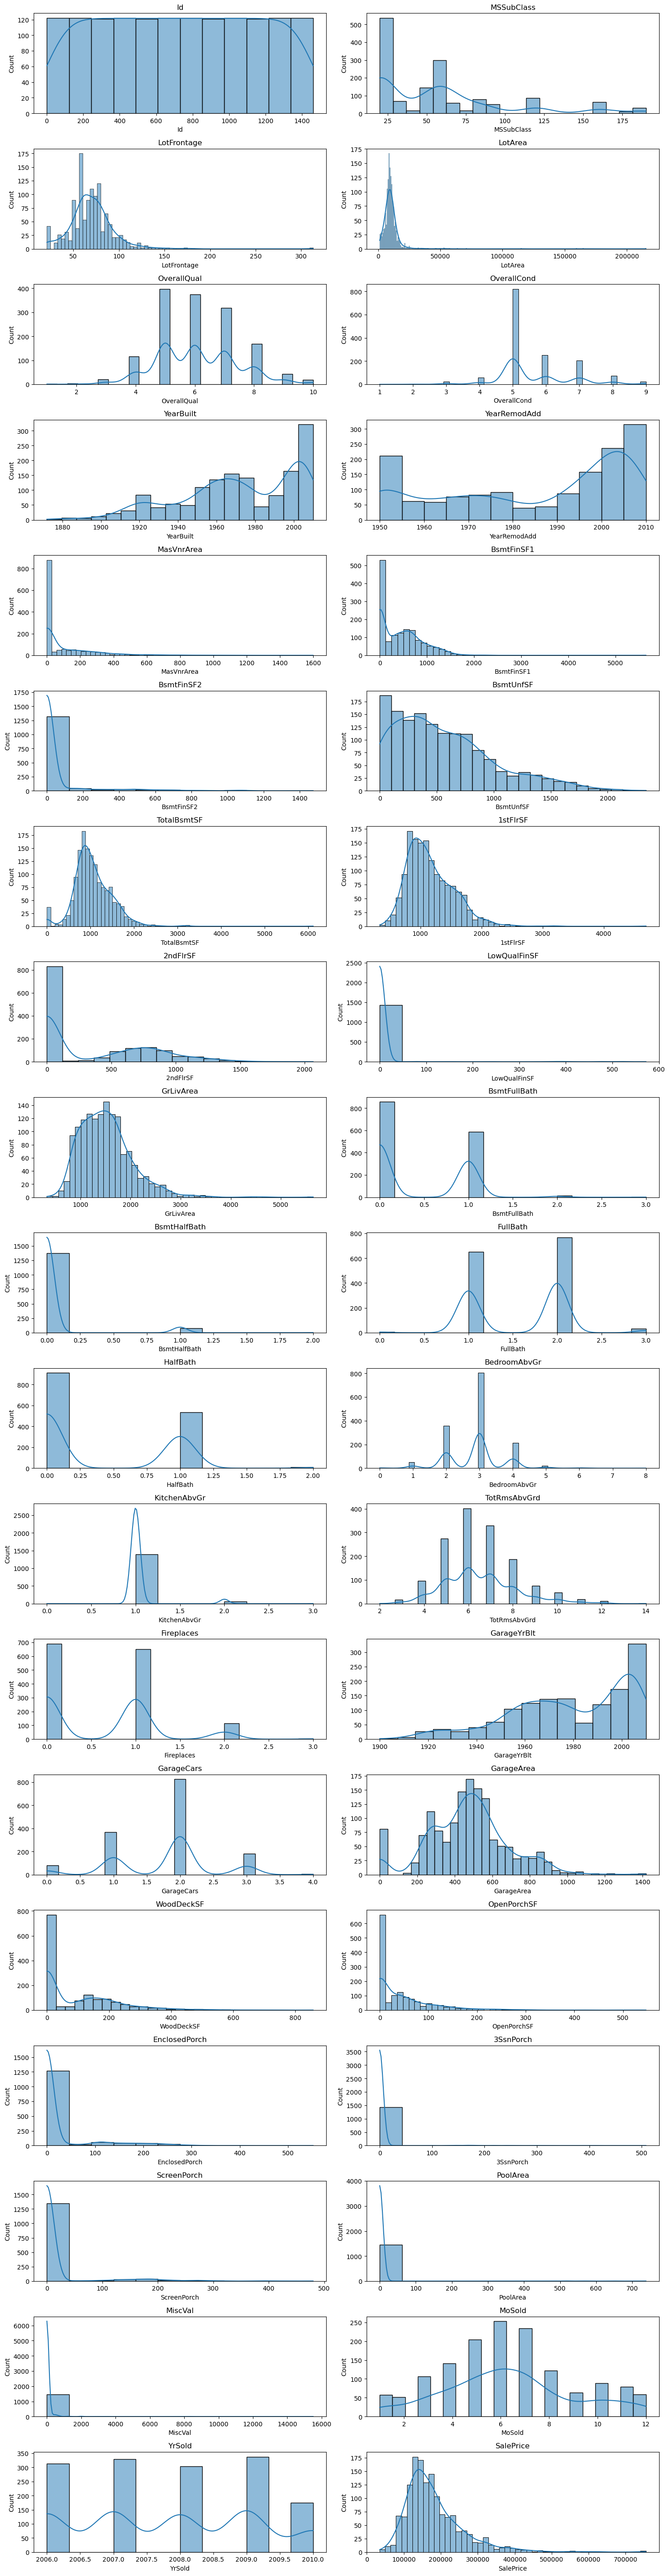

In [15]:
plt.figure(figsize=(15,60),facecolor='white')
for i, col in enumerate(num_col):
    plt.subplot(len(num_col)//2+1,2,i+1)
    sns.histplot(x=df[col],data=df,kde=True)
    plt.title(col, fontsize=12, rotation=0, wrap=True)
plt.tight_layout()
plt.show()
    

#### Findings:

1. SalePrice and most area variables (GrLivArea, LotArea, basement/porch sqft) are right-skewed.
2. Many "amenity" variables are zero-inflated (pools, porches, 2nd floor, masonry veneer) → consider engineering binary "has feature" flags alongside the continuous value, or two-part models.
3. Quality/condition and room-count variables are discrete/ordinal, best treated as ordinal or one-hot encoded categoricals rather than pure continuous inputs.
4. MSSubClass and Id are misleading as numeric — MSSubClass should be recoded as categorical, and Id dropped entirely.
5. Recency bias: A large share of homes were built or remodeled after 2000, so the dataset skews toward newer construction, which could affect generalizability to older housing stock.

In [17]:
# selecting only Categorical value colmuns in cat_col variable

cat_col = df.select_dtypes(include='O').columns

In [18]:
#### b. Plotting Countplot for all the categorical columns

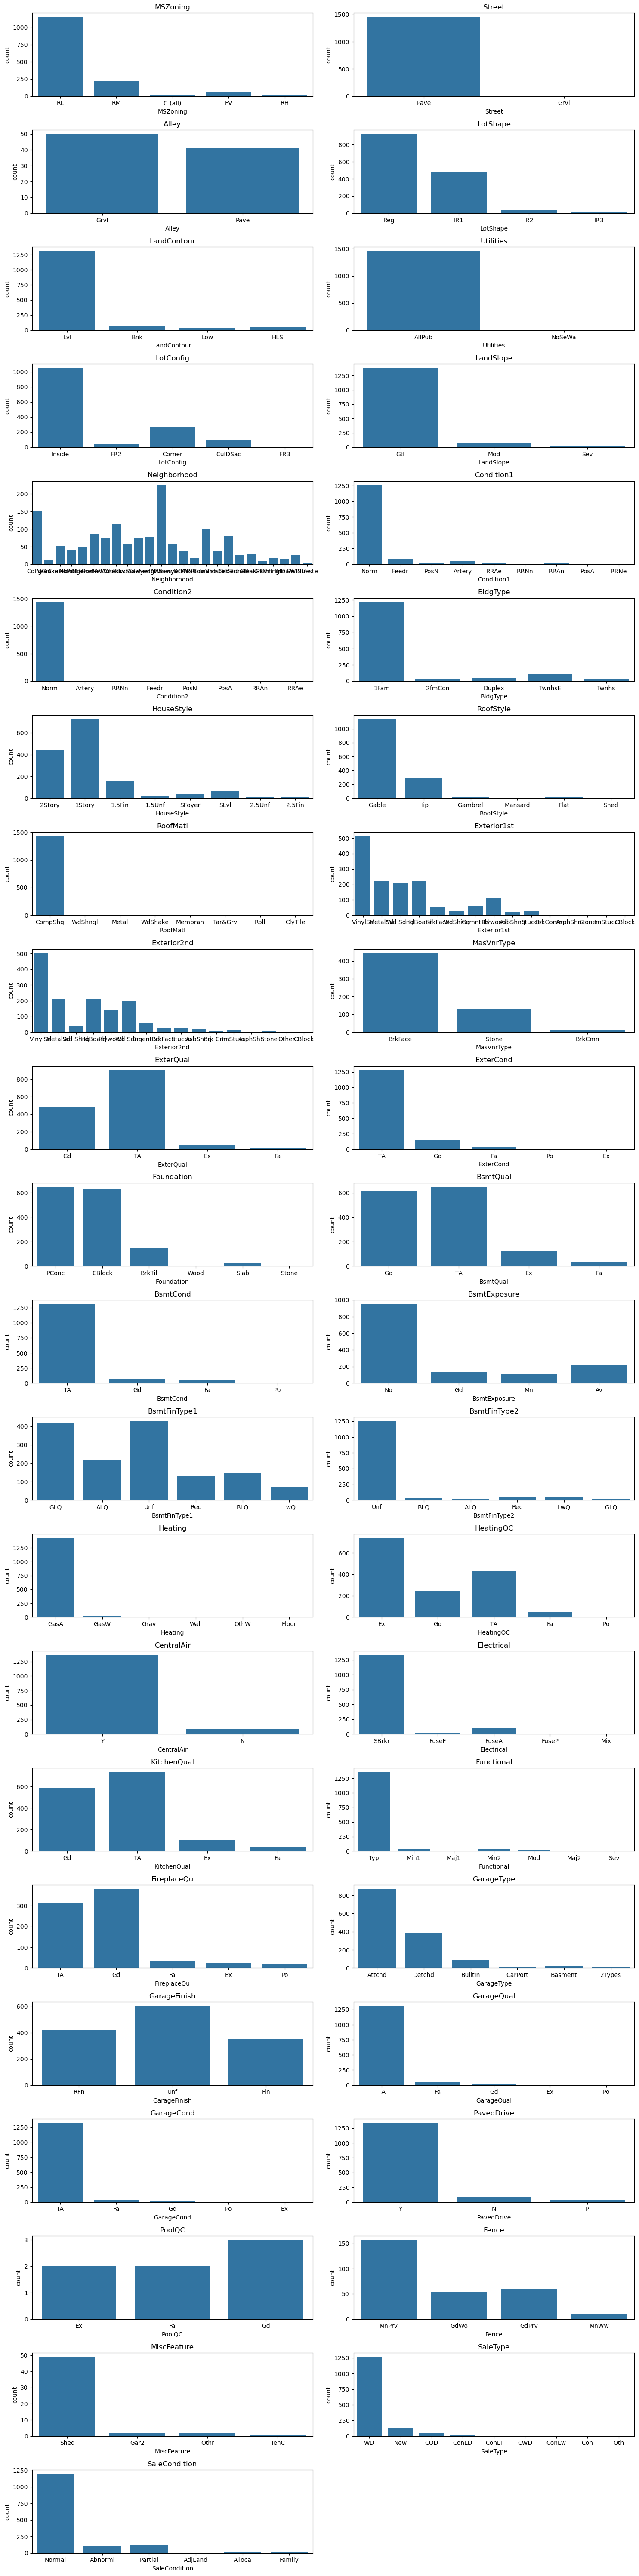

In [19]:
plt.figure(figsize=(15,60),facecolor='white')
for i, col in enumerate(cat_col):
    plt.subplot(len(cat_col)//2+1,2,i+1)
    sns.countplot(x=df[col],data=df)
    plt.title(col, fontsize=12, rotation=0, wrap=True)
plt.tight_layout()
plt.show()

#### Findings:

•  Dominant Categories:  
Most categorical variables are heavily imbalanced. For example, MSZoning is dominated by RL, Street is almost always Pave, Utilities is nearly always AllPub, and Functional is overwhelmingly Typ.

•  Rare Categories (Potential Outliers):  
Several features have categories with very few samples, such as PoolQC, MiscFeature, Utilities, RoofMatl, and Condition2. These rare categories may introduce noise and should be grouped into “Other” or dropped if not useful.

•  Moderately Balanced Features:  
Variables like Neighborhood, HouseStyle, and GarageType show a wider spread across categories, making them strong predictors. However, some rare levels within them still need careful handling.

•  Ordinal Quality Features:  
Features such as ExterQual, KitchenQual, GarageQual, BsmtQual follow an ordered scale (Ex > Gd > TA > Fa > Po). These should be encoded as ordinal values rather than one-hot to preserve their ranking.

•  Transaction & Market Features:  
SaleCondition and SaleType are dominated by one or two categories (Normal, WD), with others being rare. They capture transaction type but may require grouping for stability.

#### c. Plotting Boxplot for all numerical columns

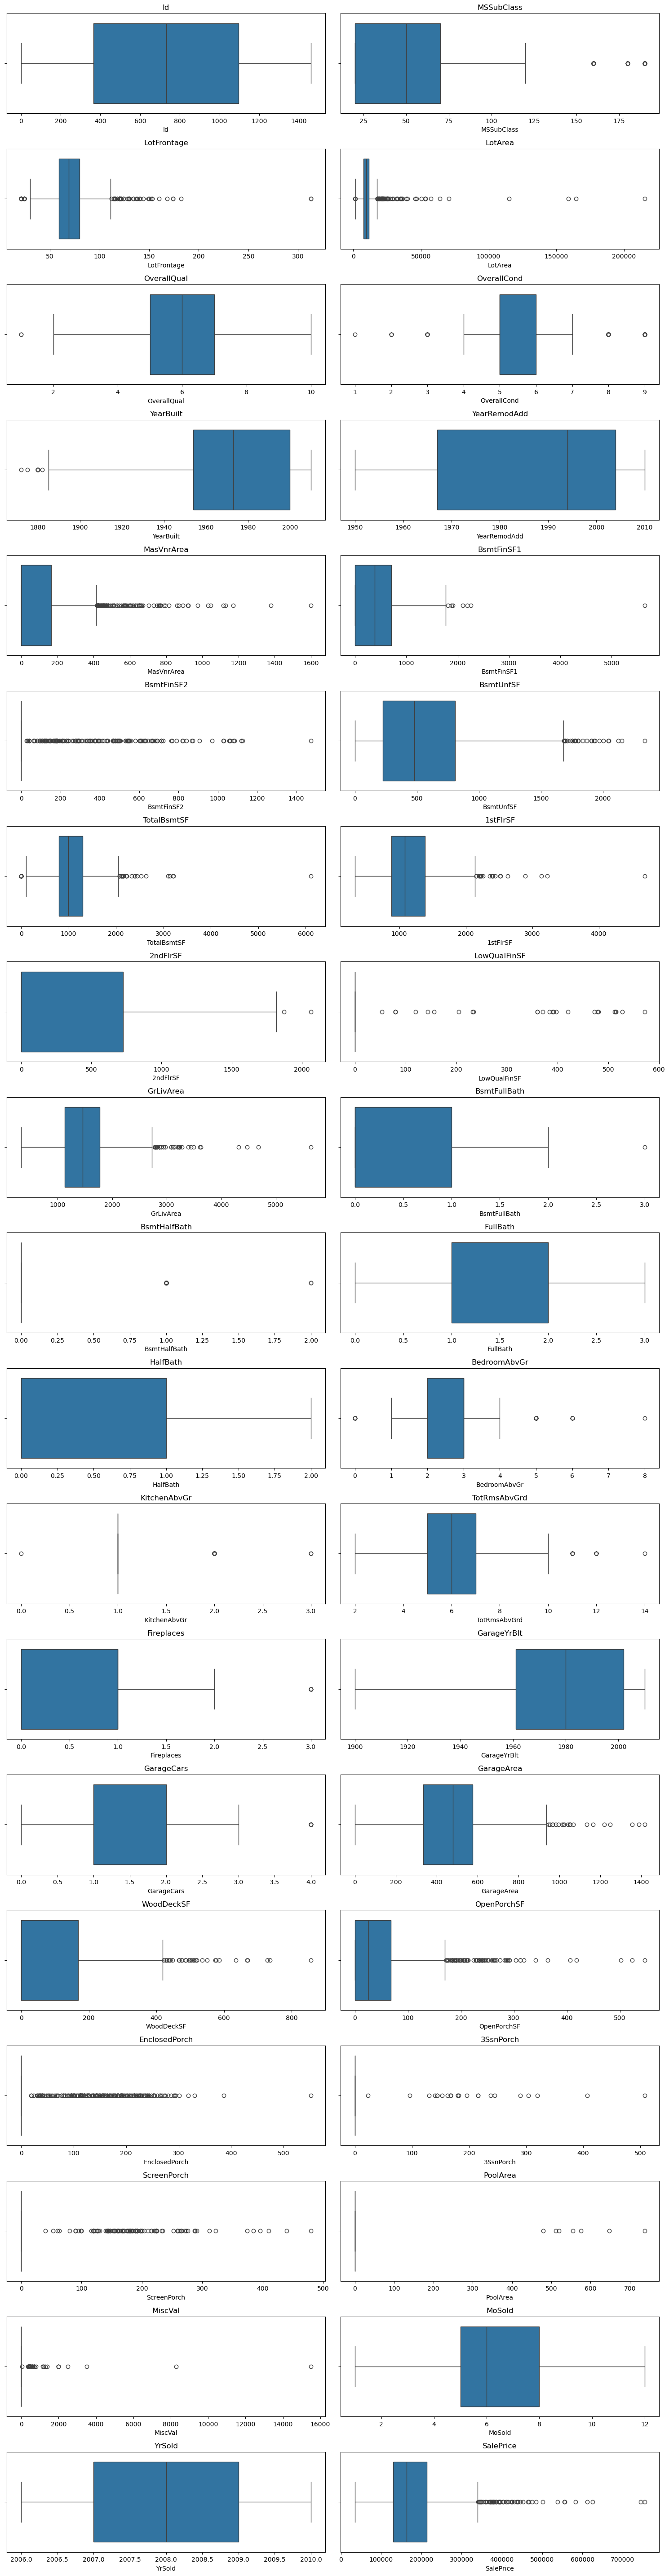

In [22]:
# Plotting Boxplots to check the Outliers

plt.figure(figsize=(15,60),facecolor='white')
for i, col in enumerate(num_col):
    plt.subplot(len(num_col)//2+1,2,i+1)
    sns.boxplot(x=df[col],data=df, orient='h')
    plt.title(col, fontsize=12, rotation=0, wrap=True)
plt.tight_layout()
plt.show()

#### Observations from Boxplot:

### 2. Multivariate Analysis - Heatmap for correlation

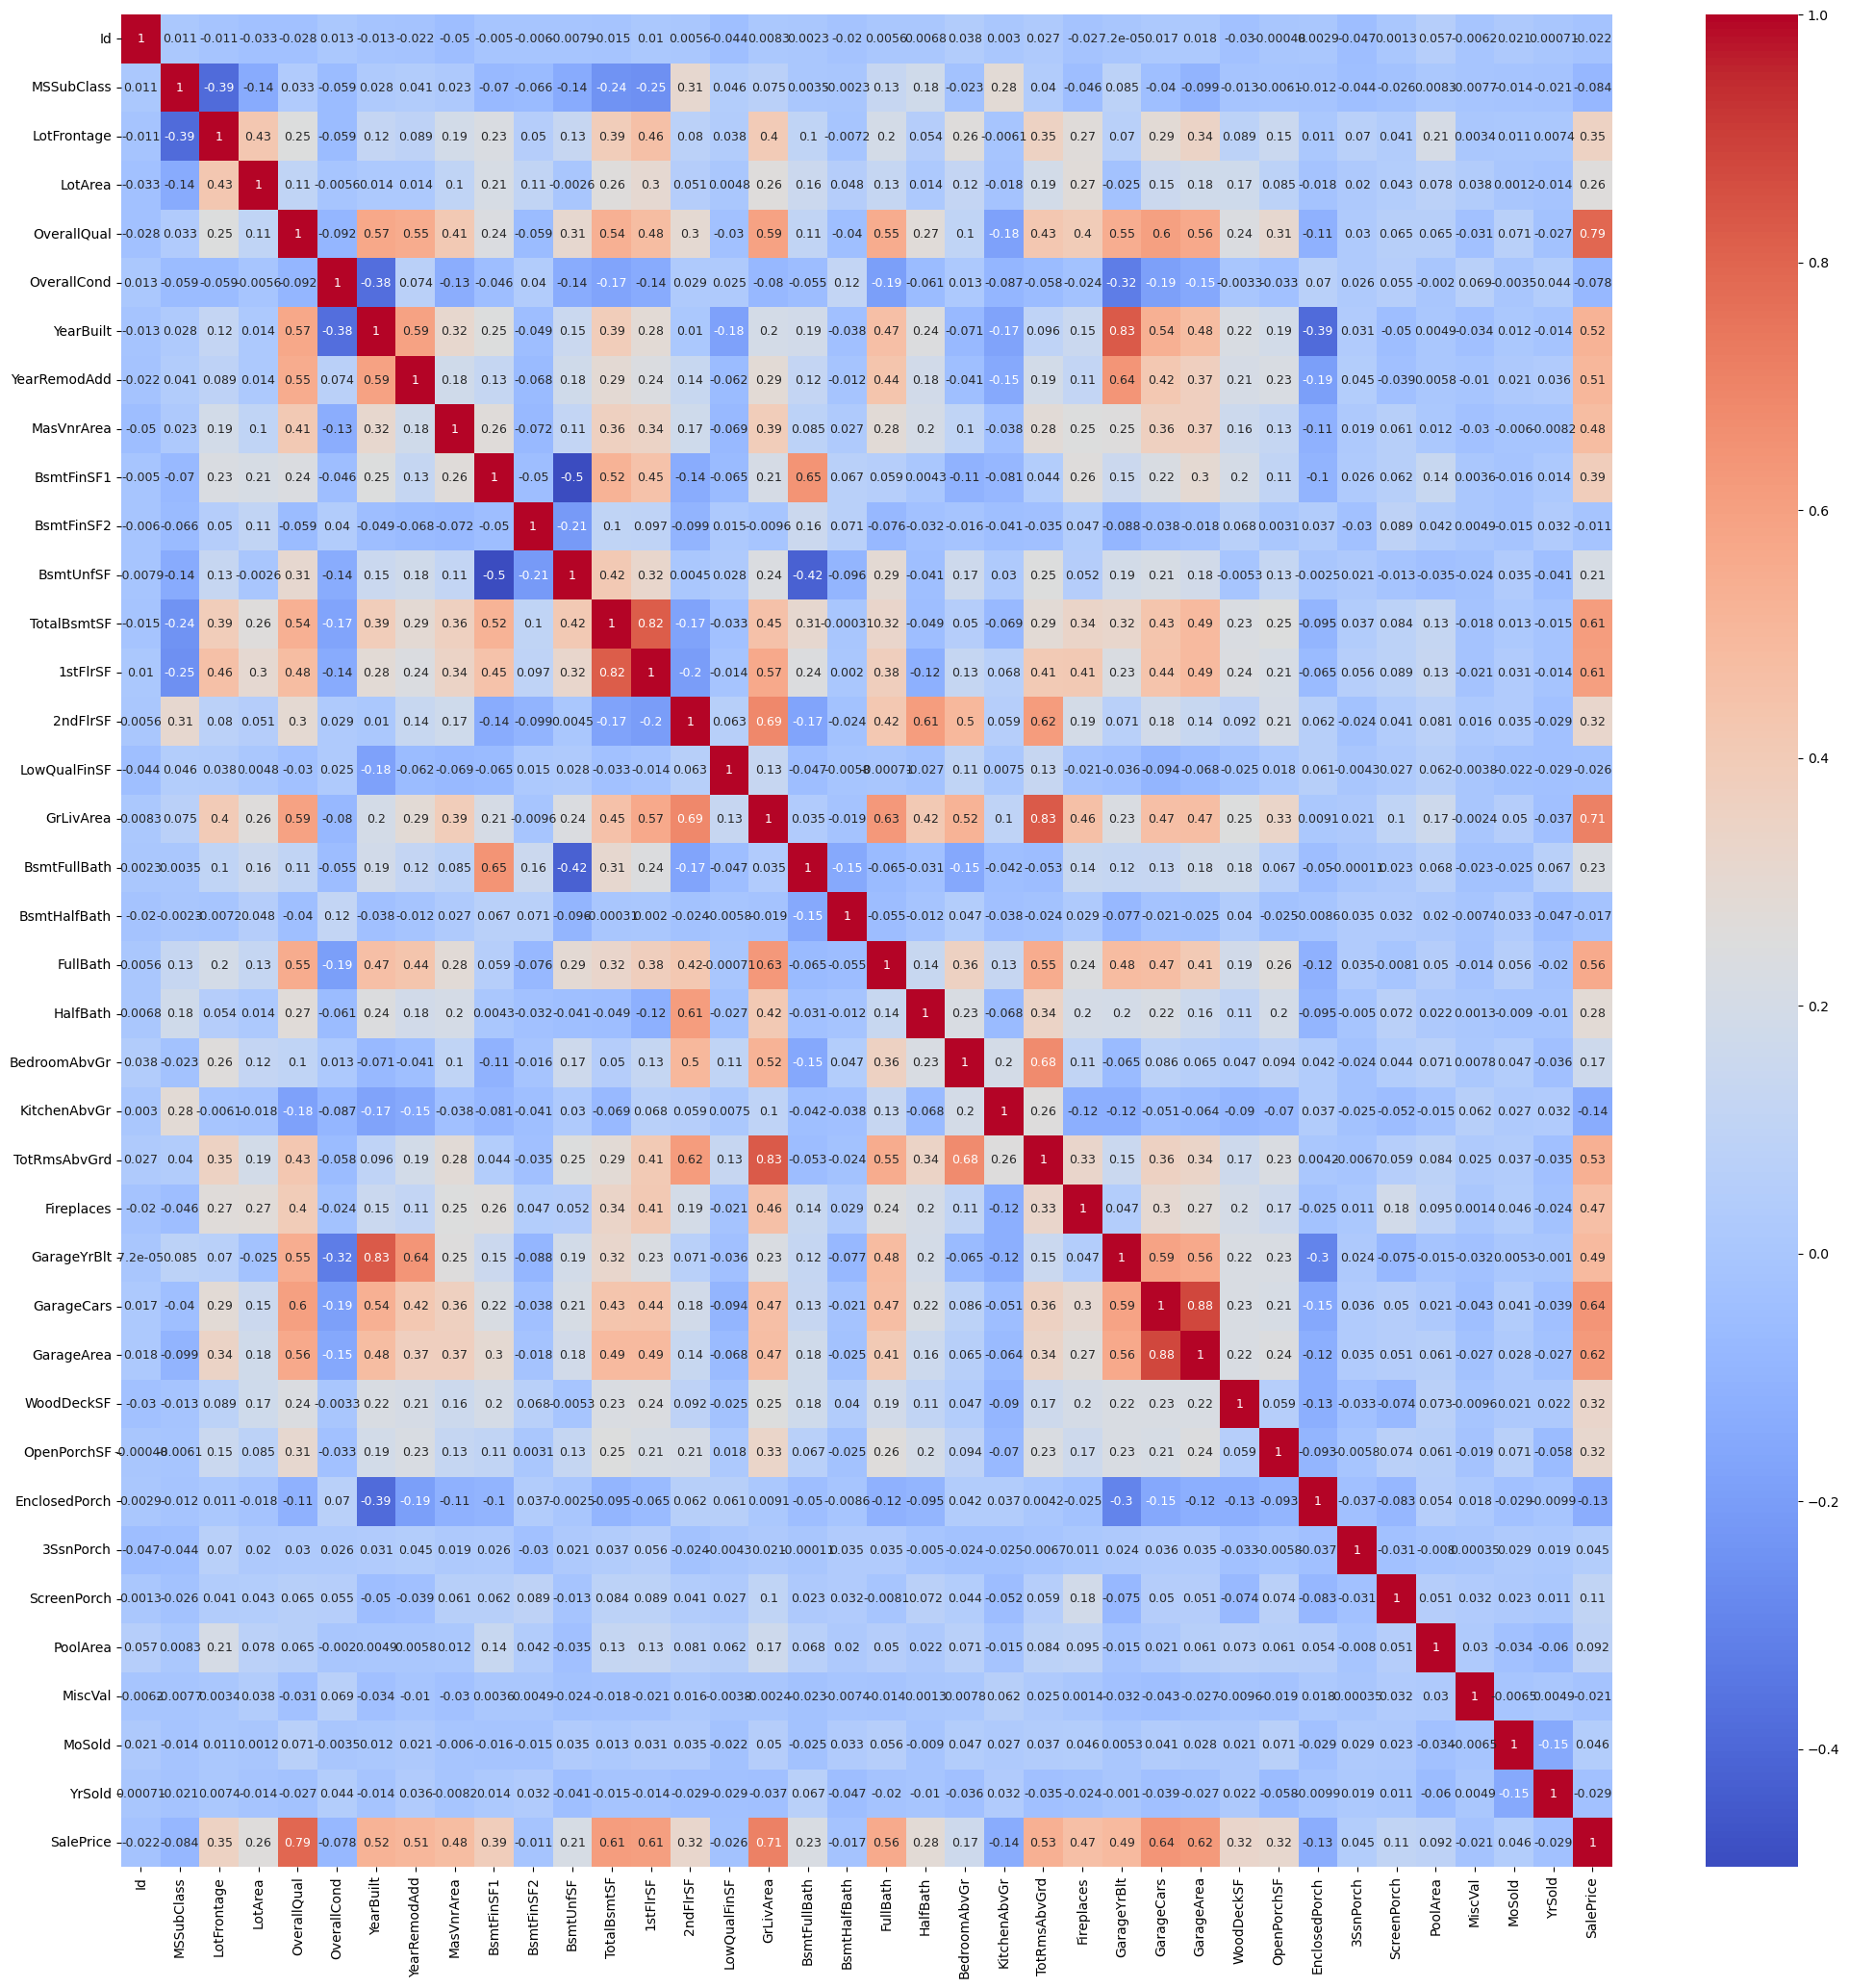

In [25]:
plt.figure(figsize=(25, 25))  # width, height in inches
sns.heatmap(df.select_dtypes(include=['int','float']).corr(),annot=True,cmap='coolwarm',annot_kws={"size":9})
plt.show()

## Data Preprocessing

### Handling Null Values

In [28]:
# ------------------------------------------------------------------

print(f"Missing values per column (top 15):")
print(df.isnull().sum().sort_values(ascending=False).head(15))

# ------------------------------------------------------------------
# 1. Missing-value handling
#    Two categories of "NA means something" columns are handled explicitly
#    (common in Ames-style housing data); everything else falls back to a
#    generic median/mode imputation fit on train only.
# ------------------------------------------------------------------
# Columns where NA genuinely means "this feature doesn't exist" (categorical)
NONE_MEANS_ABSENT_CAT = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature", "MasVnrType",
]
# Columns where NA genuinely means "0 of this feature" (numeric)
ZERO_MEANS_ABSENT_NUM = [
    "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "BsmtFullBath", "BsmtHalfBath", "GarageYrBlt", "GarageCars", "GarageArea",
]

for col in NONE_MEANS_ABSENT_CAT:
    if col in df.columns:
        df[col] = df[col].fillna("None")

for col in ZERO_MEANS_ABSENT_NUM:
    if col in df.columns:
        df[col] = df[col].fillna(0)

print(f"\nRemaining missing values after explicit None/0 fill: {df.isnull().sum().sum()}")

Missing values per column (top 15):
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
dtype: int64

Remaining missing values after explicit None/0 fill: 260


### 2. Feature engineering (guarded by column-existence checks)

In [30]:

# ------------------------------------------------------------------
def safe_cols_exist(cols):
    return all(c in df.columns for c in cols)

engineered_cols = []

sqft_parts = [c for c in ["TotalBsmtSF", "1stFlrSF", "2ndFlrSF"] if c in df.columns]
if len(sqft_parts) >= 2:
    df["TotalSF"] = df[sqft_parts].sum(axis=1)
    engineered_cols.append("TotalSF")

if safe_cols_exist(["YrSold", "YearBuilt"]):
    df["HouseAge"] = (df["YrSold"] - df["YearBuilt"]).clip(lower=0)
    engineered_cols.append("HouseAge")

if safe_cols_exist(["YrSold", "YearRemodAdd"]):
    df["YearsSinceRemodel"] = (df["YrSold"] - df["YearRemodAdd"]).clip(lower=0)
    engineered_cols.append("YearsSinceRemodel")

if safe_cols_exist(["YearBuilt", "YearRemodAdd"]):
    df["WasRemodeled"] = (df["YearRemodAdd"] != df["YearBuilt"]).astype(int)
    engineered_cols.append("WasRemodeled")

if safe_cols_exist(["OverallQual", "OverallCond"]):
    df["QualCondInteraction"] = df["OverallQual"] * df["OverallCond"]
    engineered_cols.append("QualCondInteraction")

bath_parts = [c for c in ["FullBath", "HalfBath", "BsmtFullBath", "BsmtHalfBath"] if c in df.columns]
if len(bath_parts) >= 2:
    df["TotalBathrooms"] = (
        df.get("FullBath", 0) + df.get("BsmtFullBath", 0)
        + 0.5 * (df.get("HalfBath", 0) + df.get("BsmtHalfBath", 0))
    )
    engineered_cols.append("TotalBathrooms")

if "OverallQual" in df.columns and "TotalSF" in df.columns:
    df["QualSFInteraction"] = df["OverallQual"] * df["TotalSF"]
    engineered_cols.append("QualSFInteraction")

if "PoolArea" in df.columns:
    df["HasPool"] = (df["PoolArea"] > 0).astype(int)
    engineered_cols.append("HasPool")
if "GarageArea" in df.columns:
    df["HasGarage"] = (df["GarageArea"] > 0).astype(int)
    engineered_cols.append("HasGarage")
if "TotalBsmtSF" in df.columns:
    df["HasBasement"] = (df["TotalBsmtSF"] > 0).astype(int)
    engineered_cols.append("HasBasement")

print(f"\nEngineered {len(engineered_cols)} new features: {engineered_cols}")


Engineered 10 new features: ['TotalSF', 'HouseAge', 'YearsSinceRemodel', 'WasRemodeled', 'QualCondInteraction', 'TotalBathrooms', 'QualSFInteraction', 'HasPool', 'HasGarage', 'HasBasement']


### 3. Split X / y, identify column types

In [32]:
df = df.dropna(subset=[TARGET])  # can't train/score rows with unknown target
y_raw = df[TARGET].astype(float)
X = df.drop(columns=[TARGET])

# Drop an ID column if present — it's not predictive and would just add noise
for id_col in ["Id", "id", "ID"]:
    if id_col in X.columns:
        X = X.drop(columns=[id_col])

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print(f"\nTotal columns (excl. target): {X.shape[1]}")
print(f"Numerical columns : {len(num_cols)}")
print(f"Categorical columns: {len(cat_cols)}")


Total columns (excl. target): 89
Numerical columns : 46
Categorical columns: 43


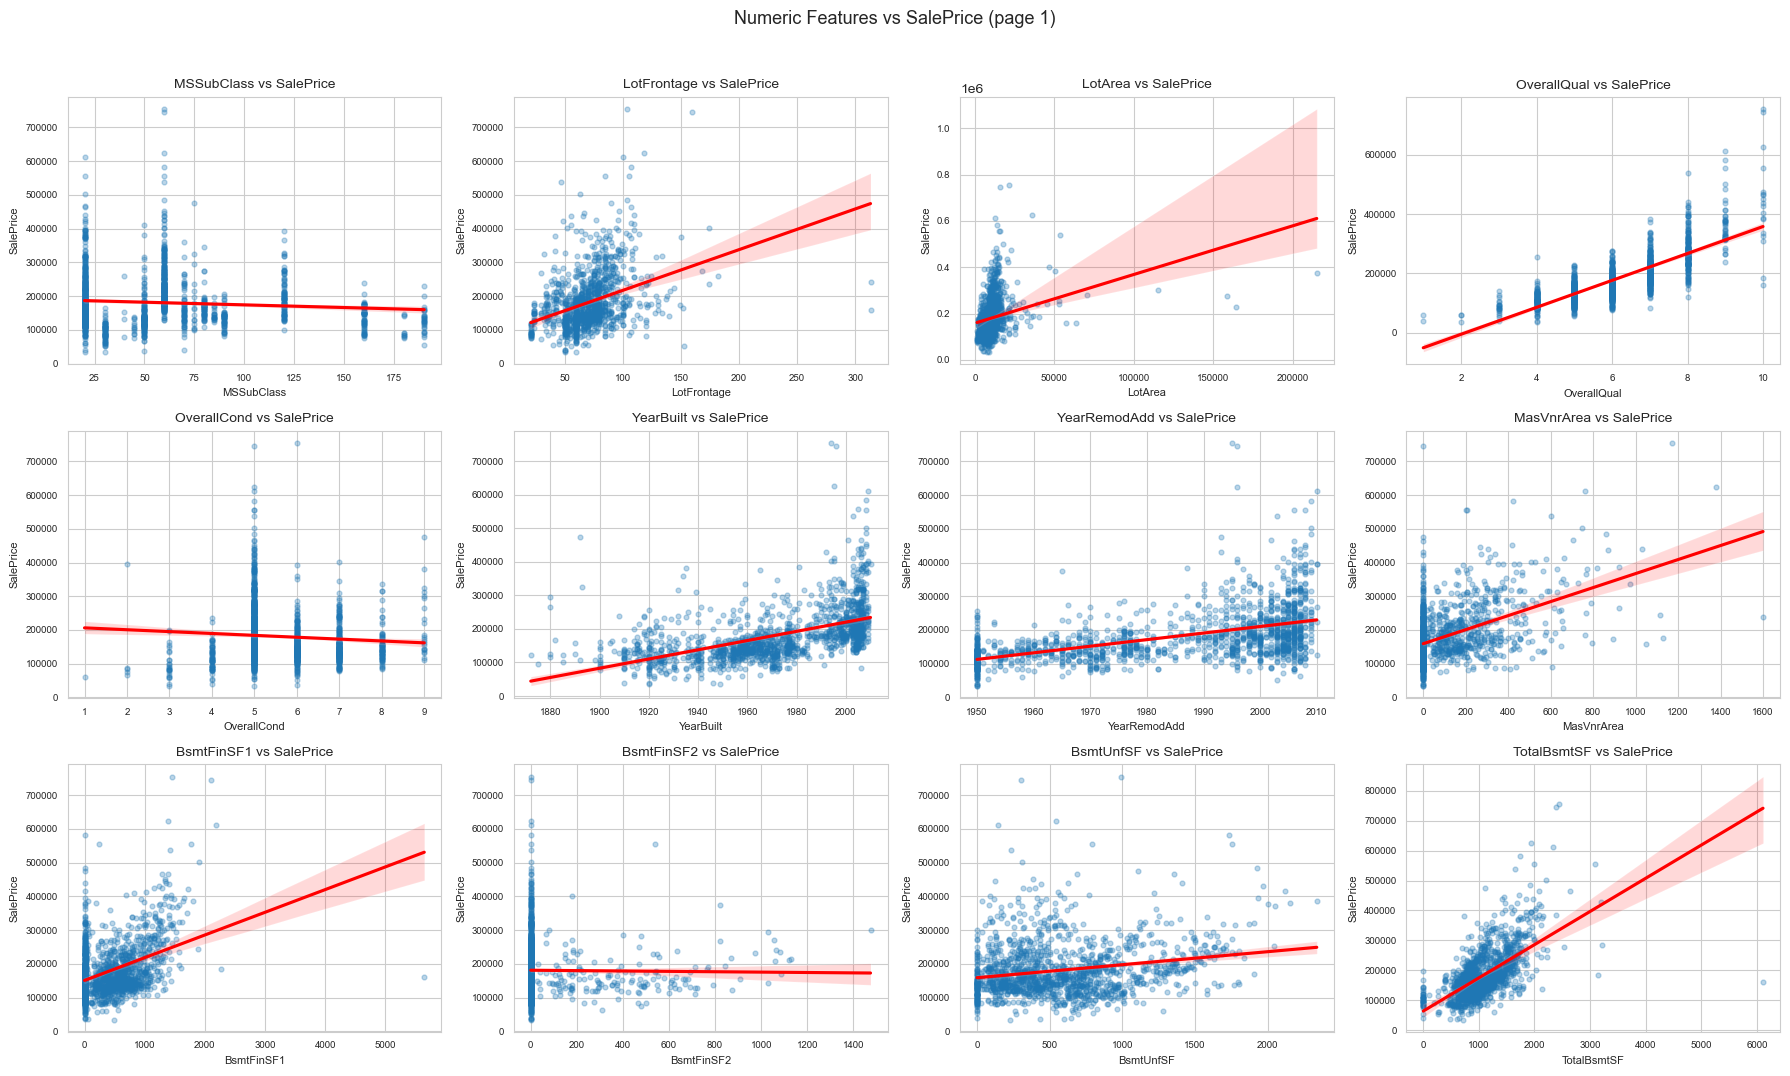

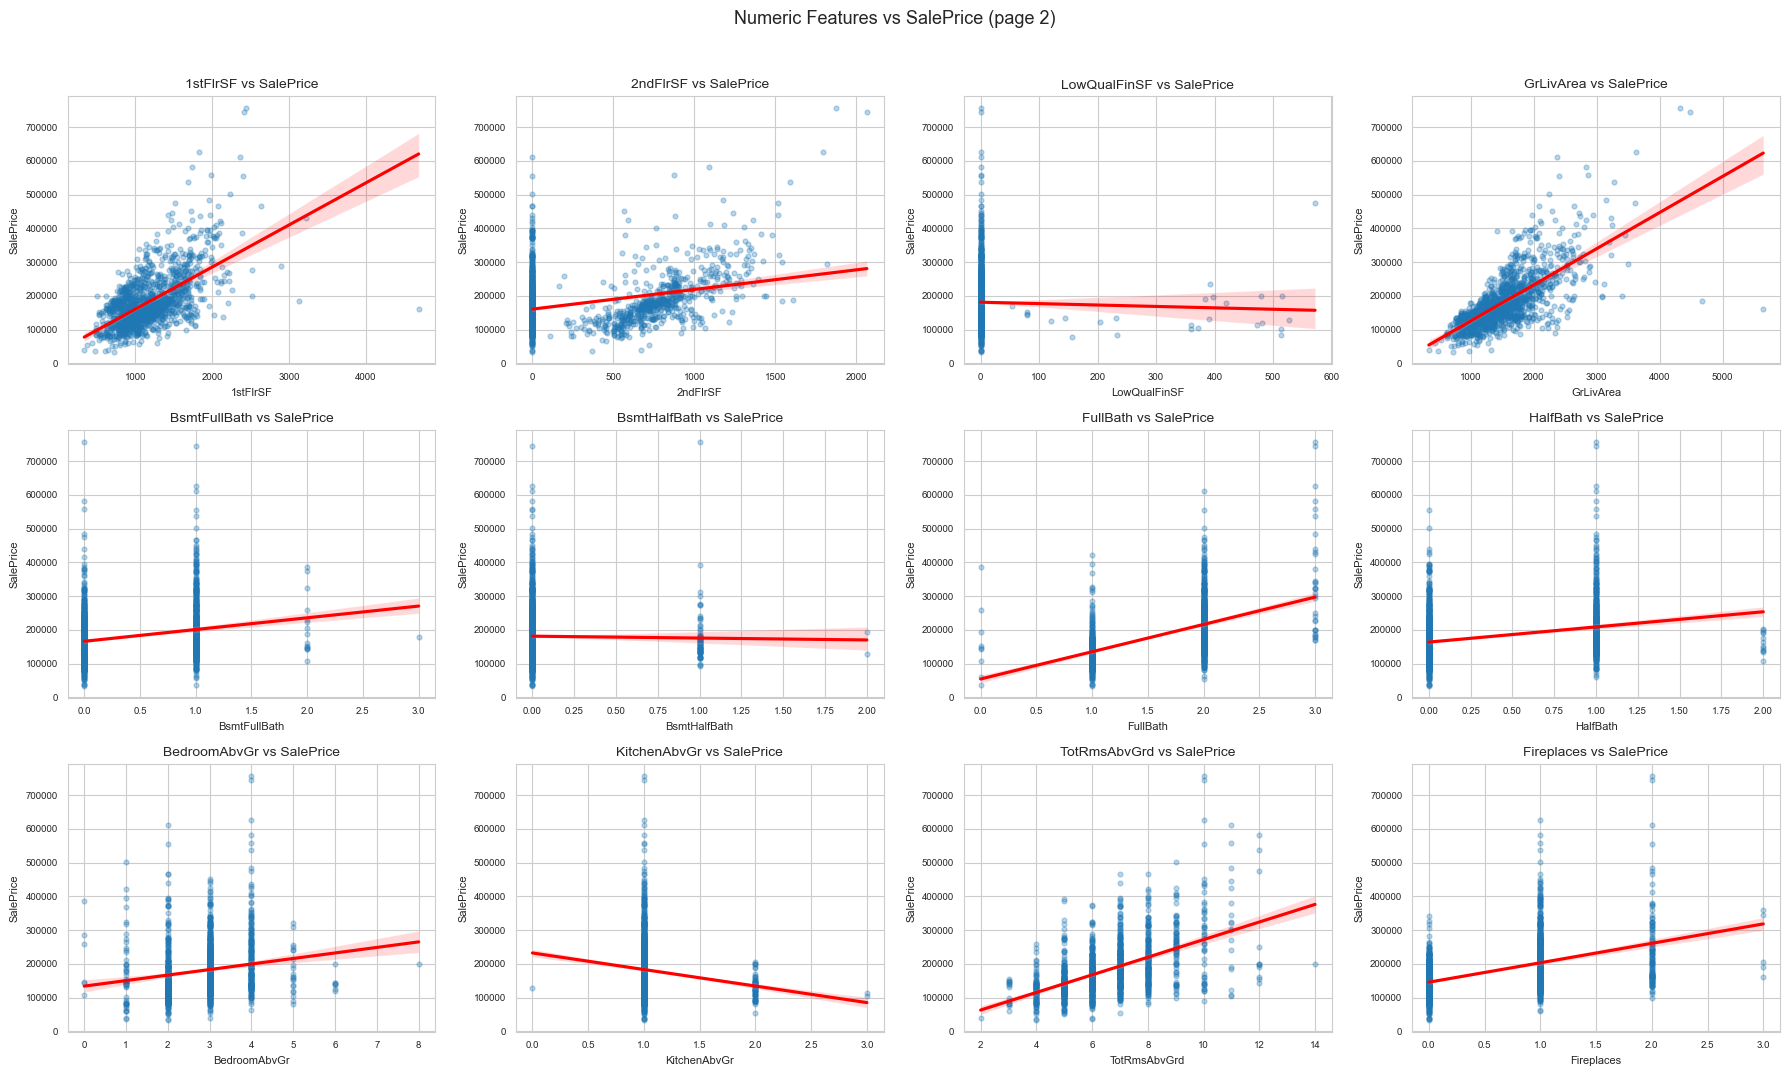

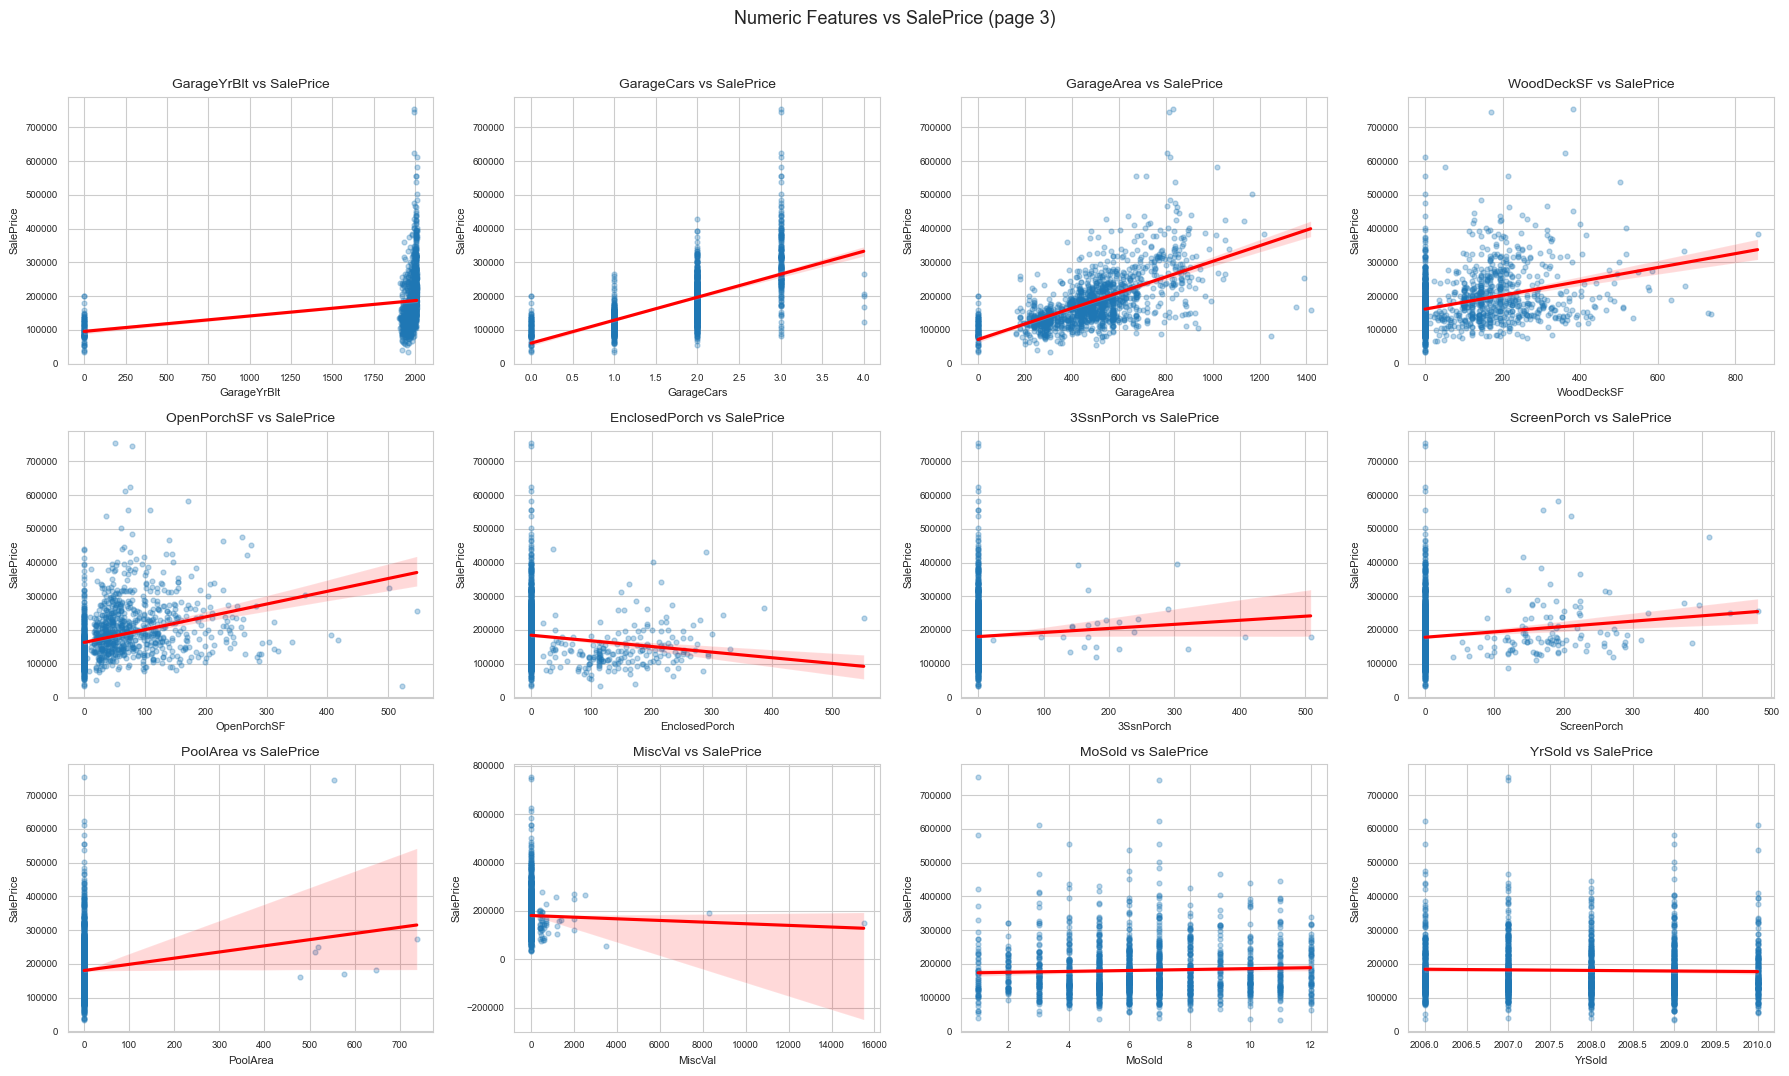

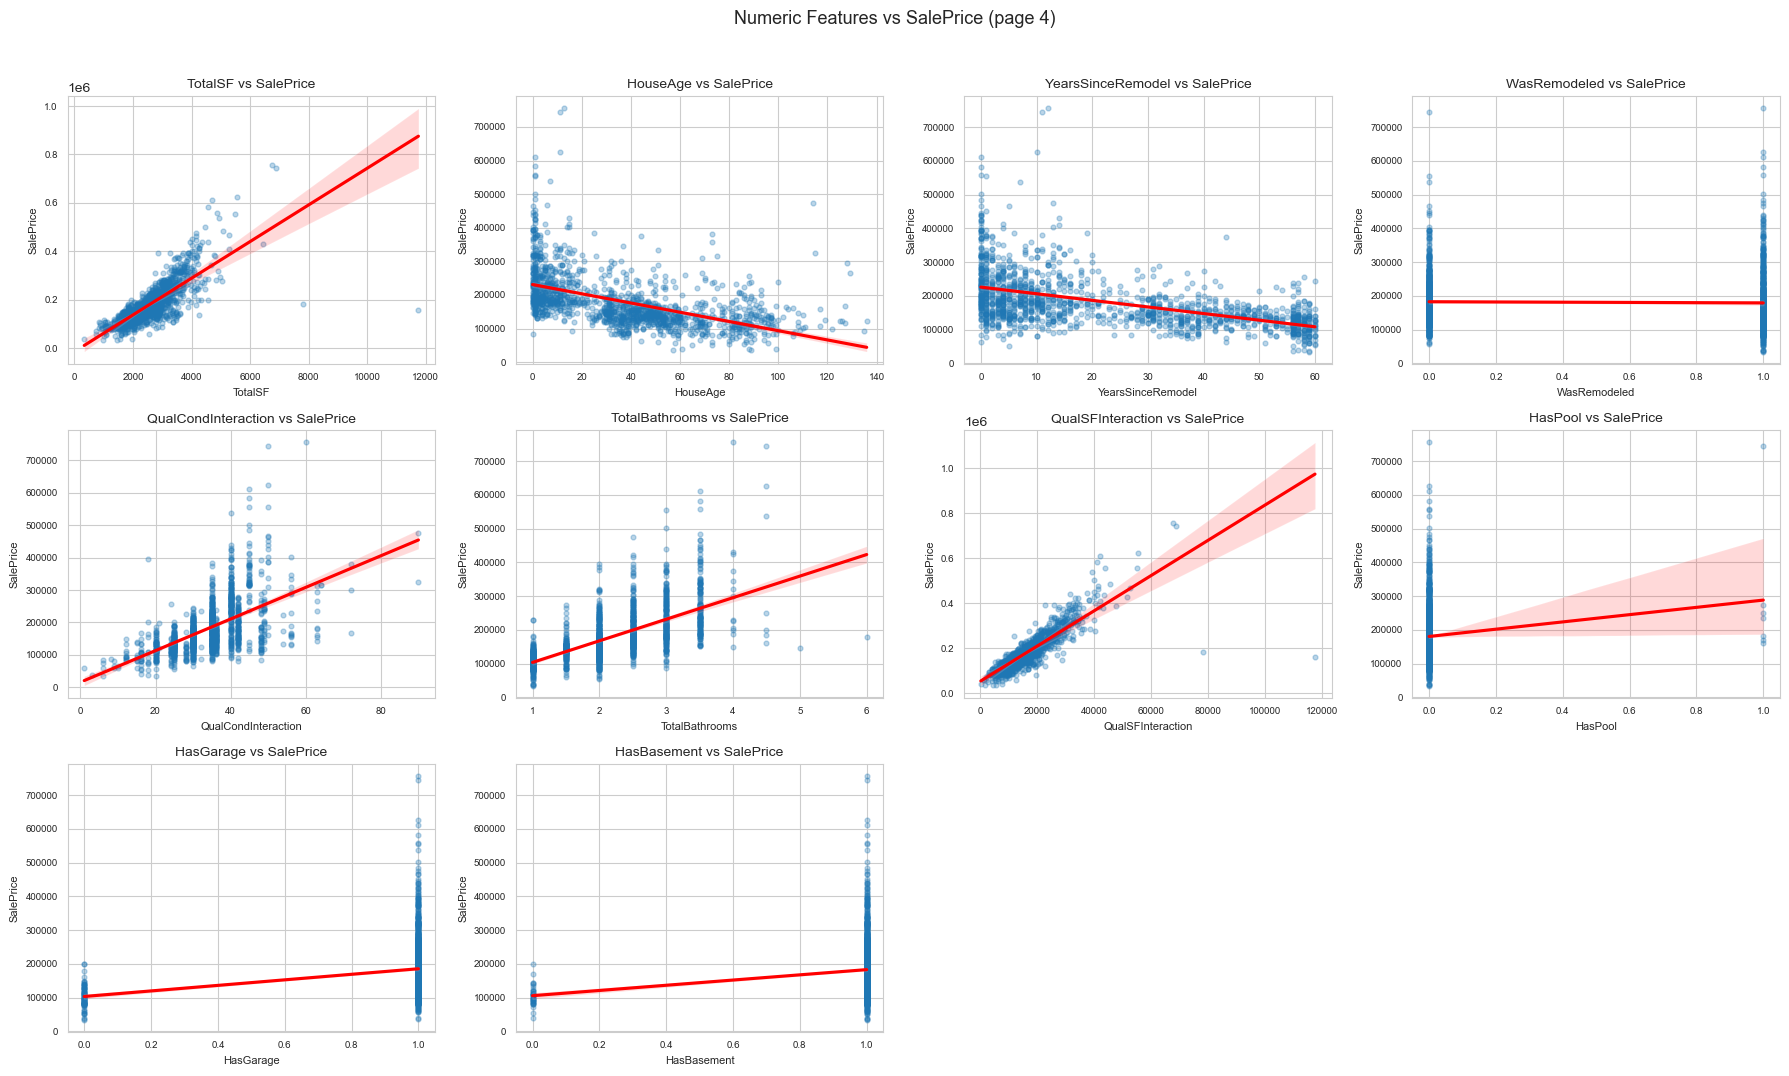

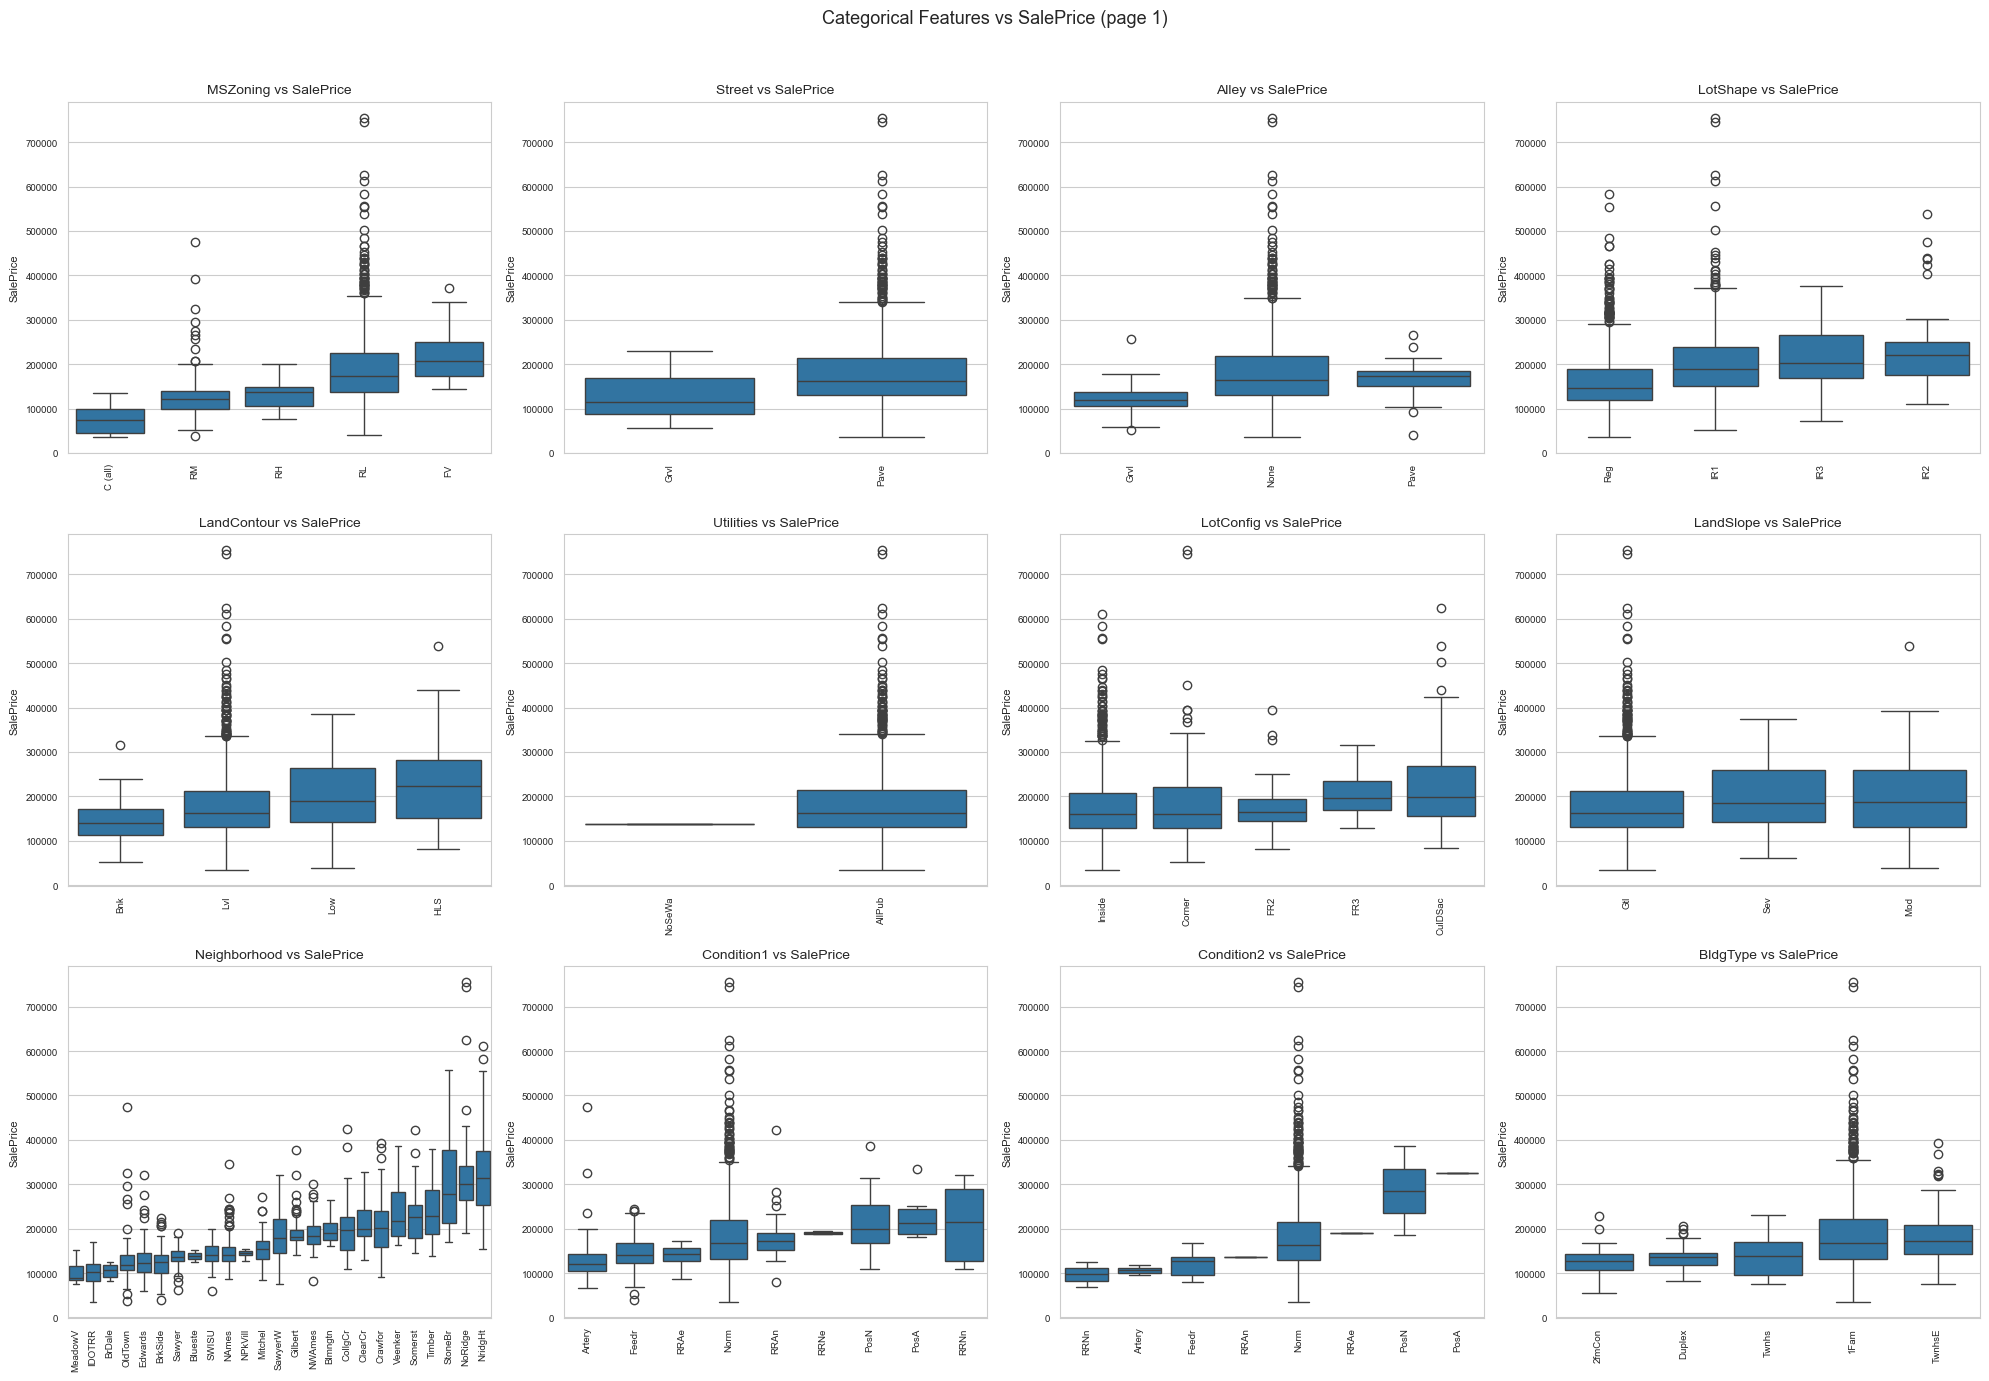

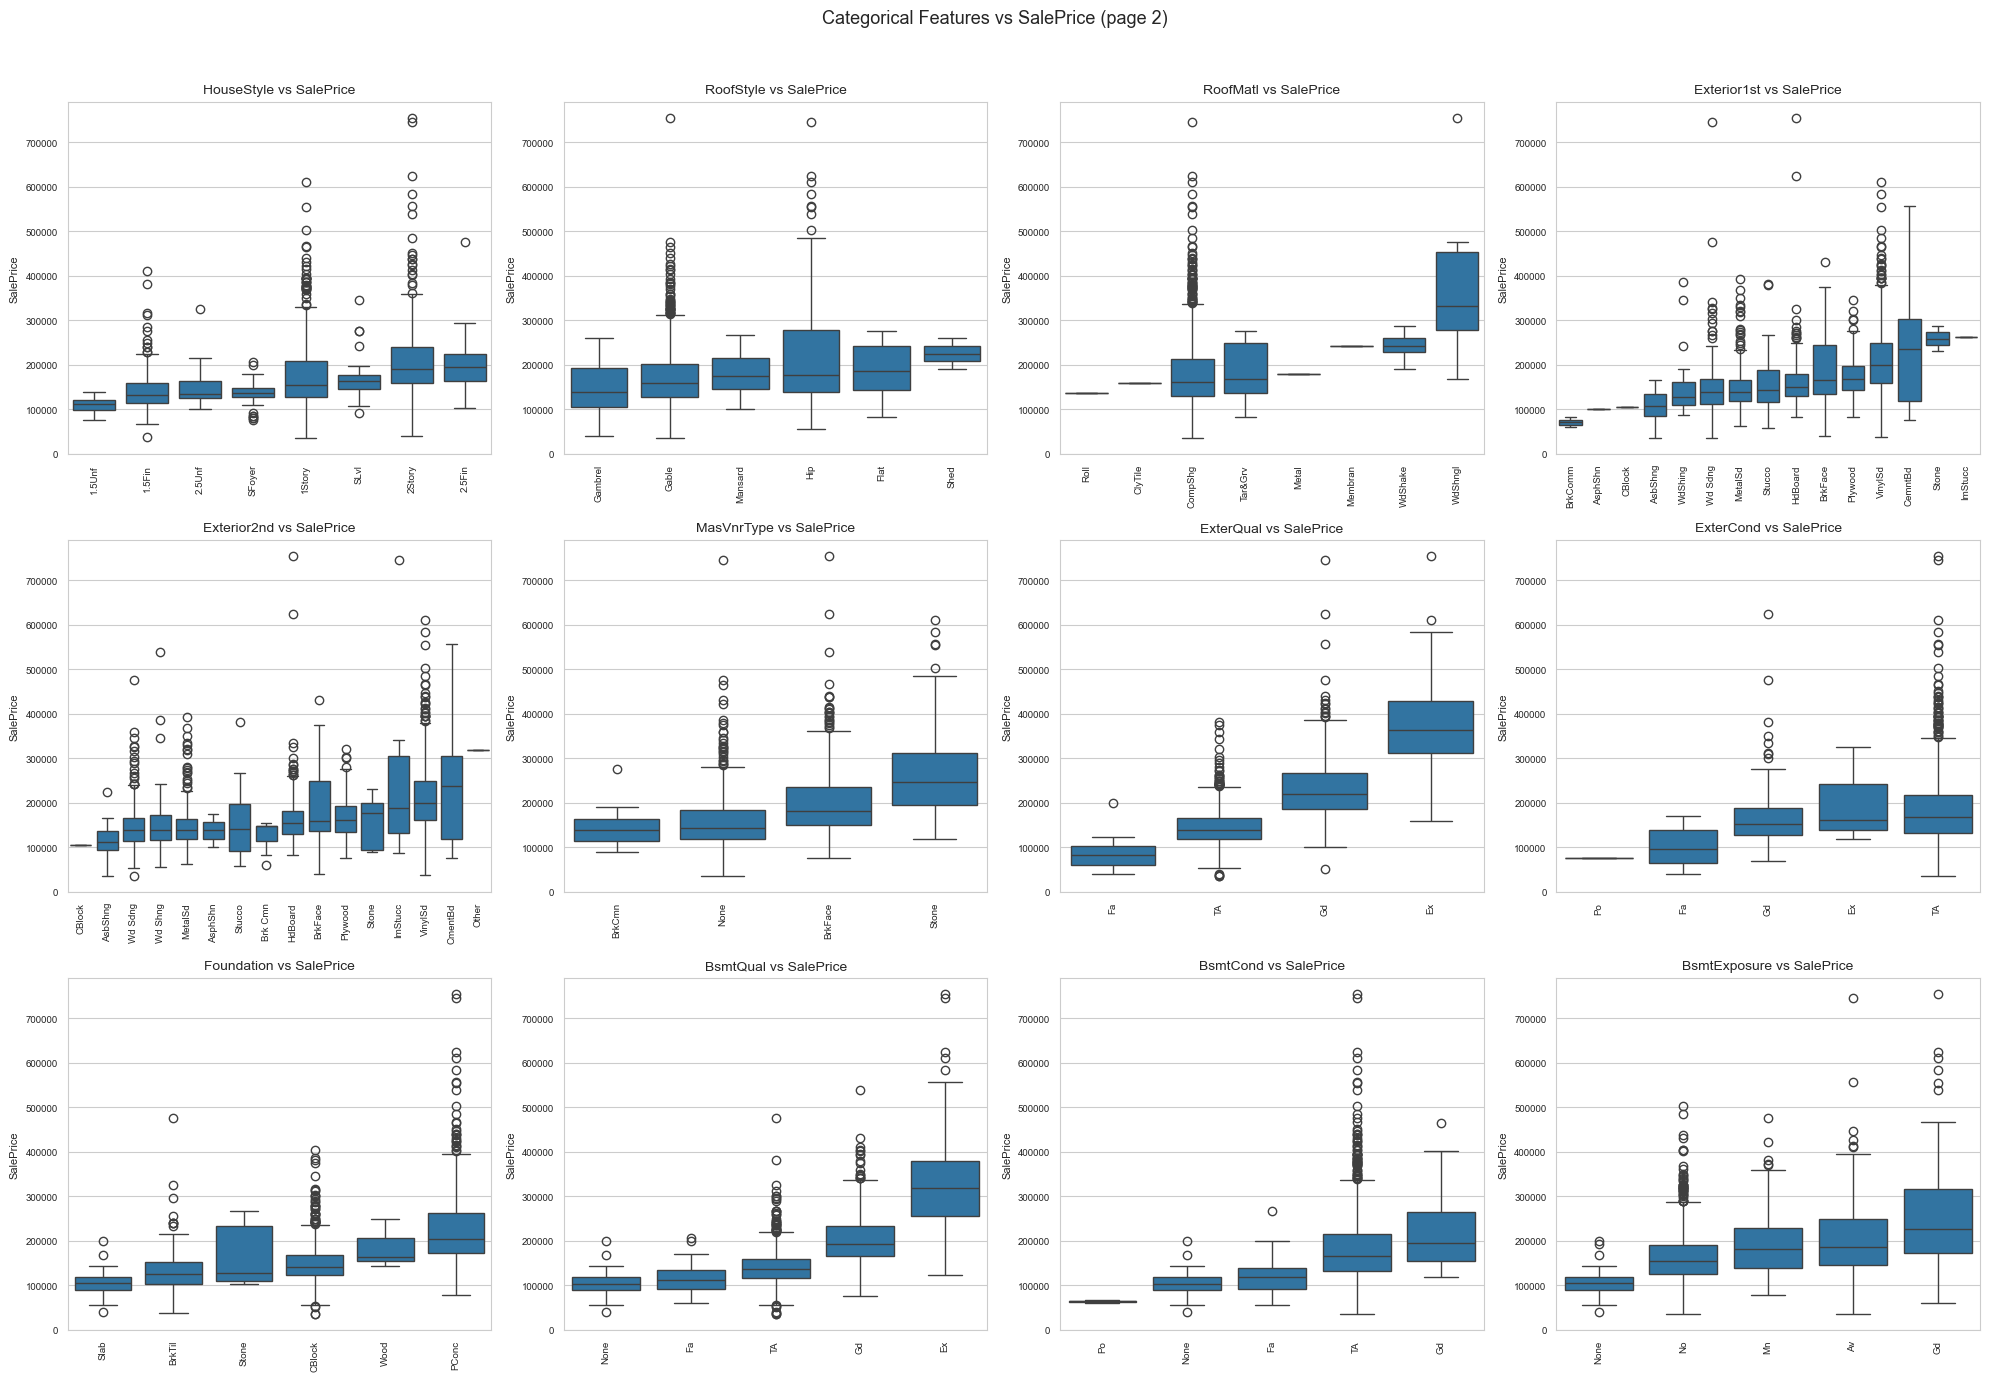

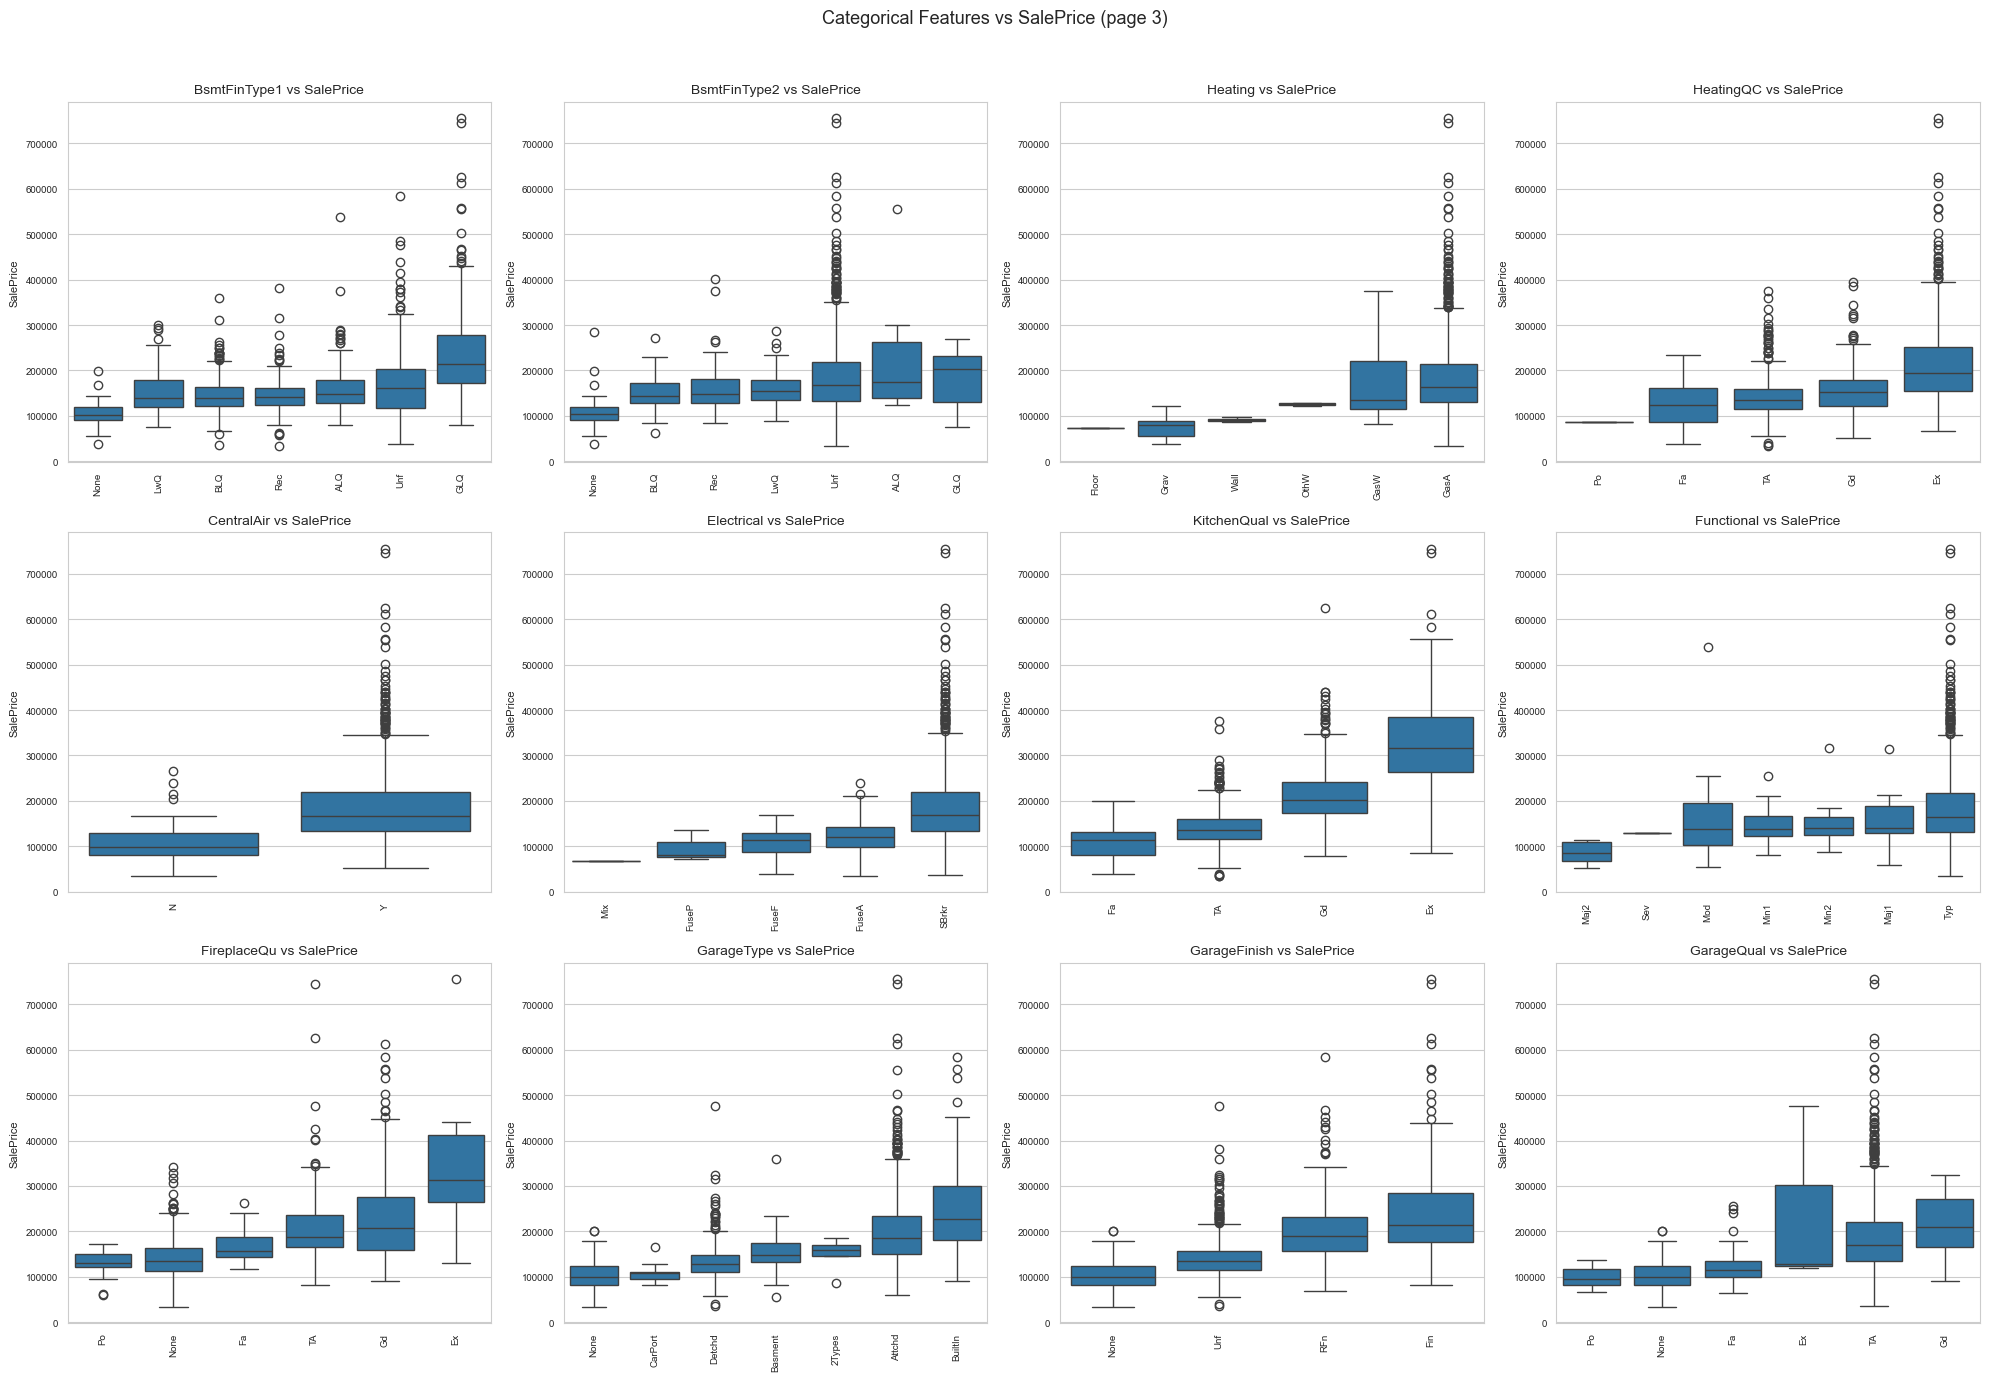

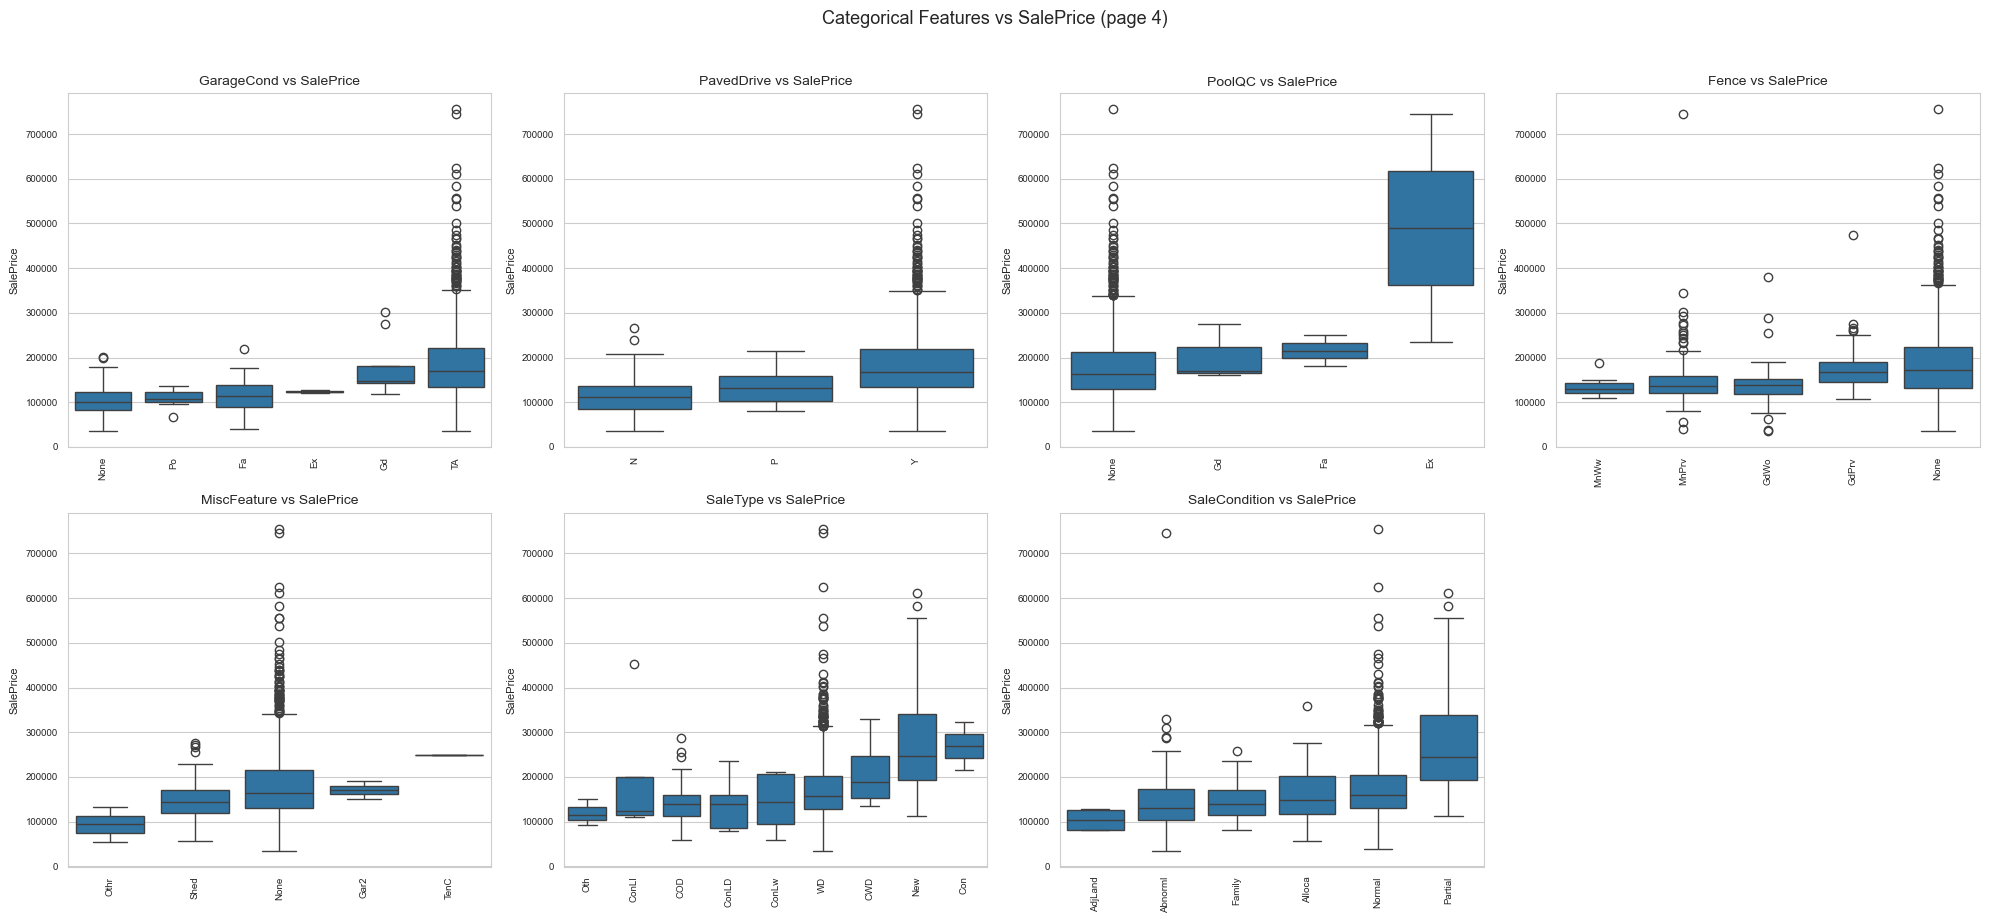

In [33]:
"""
Bivariate Analysis — All Features vs SalePrice

- Numeric features -> scatter plot + regression line vs SalePrice
- Categorical features -> boxplot of SalePrice by category, ordered by median
  price (low to high) so the pattern is easy to read at a glance
  
"""

sns.set_style("whitegrid")

PLOTS_PER_FIGURE = 12   # how many subplots per figure/page
COLS_PER_ROW = 4        # subplot grid width

# ------------------------------------------------------------------
# 1. Numeric features vs SalePrice — scatter + regression line
# ------------------------------------------------------------------
numeric_features = list(num_cols)

for start in range(0, len(numeric_features), PLOTS_PER_FIGURE):
    batch = numeric_features[start:start + PLOTS_PER_FIGURE]
    n_rows = int(np.ceil(len(batch) / COLS_PER_ROW))

    fig, axes = plt.subplots(n_rows, COLS_PER_ROW, figsize=(COLS_PER_ROW * 4.5, n_rows * 3.5))
    axes = np.array(axes).flatten()

    for i, col in enumerate(batch):
        sns.regplot(
            x=X[col], y=y_raw, ax=axes[i],
            scatter_kws={"alpha": 0.3, "s": 12}, line_kws={"color": "red"},
        )
        axes[i].set_title(f"{col} vs SalePrice", fontsize=10)
        axes[i].set_xlabel(col, fontsize=8)
        axes[i].set_ylabel("SalePrice", fontsize=8)
        axes[i].tick_params(labelsize=7)

    for j in range(len(batch), len(axes)):
        axes[j].axis("off")

    page_num = start // PLOTS_PER_FIGURE + 1
    fig.suptitle(f"Numeric Features vs SalePrice (page {page_num})", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.savefig(f"bivariate_numeric_page{page_num}.png", dpi=120, bbox_inches="tight")

# ------------------------------------------------------------------
# 2. Categorical features vs SalePrice — boxplot ordered by median price
# ------------------------------------------------------------------
categorical_features = list(cat_cols)

for start in range(0, len(categorical_features), PLOTS_PER_FIGURE):
    batch = categorical_features[start:start + PLOTS_PER_FIGURE]
    n_rows = int(np.ceil(len(batch) / COLS_PER_ROW))

    fig, axes = plt.subplots(n_rows, COLS_PER_ROW, figsize=(COLS_PER_ROW * 5, n_rows * 4.5))
    axes = np.array(axes).flatten()

    for i, col in enumerate(batch):
        plot_df = pd.DataFrame({col: X[col], "SalePrice": y_raw})
        order = plot_df.groupby(col)["SalePrice"].median().sort_values().index

        sns.boxplot(data=plot_df, x=col, y="SalePrice", order=order, ax=axes[i])
        axes[i].set_title(f"{col} vs SalePrice", fontsize=10)
        axes[i].set_xlabel("")
        axes[i].set_ylabel("SalePrice", fontsize=8)
        axes[i].tick_params(axis="x", labelrotation=90, labelsize=7)
        axes[i].tick_params(axis="y", labelsize=7)

    for j in range(len(batch), len(axes)):
        axes[j].axis("off")

    page_num = start // PLOTS_PER_FIGURE + 1
    fig.suptitle(f"Categorical Features vs SalePrice (page {page_num})", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.savefig(f"bivariate_categorical_page{page_num}.png", dpi=120, bbox_inches="tight")

# ------------------------------------------------------------------
# 3. Show everything at once, at the very end
# ------------------------------------------------------------------
plt.show()

### 4. Log-transform the target

In [35]:
y_log = np.log1p(y_raw)

binary_flag_cols = [c for c in num_cols if X[c].dropna().isin([0, 1]).all()]
skew_candidates = [c for c in num_cols if c not in binary_flag_cols]

### 5. Train/test split

In [37]:

# ------------------------------------------------------------------
X_train, X_test, y_train_log, y_test_log, y_train_raw, y_test_raw = train_test_split(
    X, y_log, y_raw, test_size=0.2, random_state=RANDOM_STATE
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train_log = y_train_log.reset_index(drop=True)
y_test_log = y_test_log.reset_index(drop=True)
y_train_raw = y_train_raw.reset_index(drop=True)
y_test_raw = y_test_raw.reset_index(drop=True)

In [38]:
# 6. Generic fallback imputation for any leftover NAs (fit on train only)
#    — most Ames-style NAs are already resolved by step 1, this is a safety net
#    for any column not covered above or from a different raw dataset.
# ------------------------------------------------------------------
for col in num_cols:
    if X_train[col].isnull().any():
        median_val = X_train[col].median()
        X_train[col] = X_train[col].fillna(median_val)
        X_test[col] = X_test[col].fillna(median_val)

for col in cat_cols:
    if X_train[col].isnull().any():
        mode_val = X_train[col].mode(dropna=True)
        mode_val = mode_val.iloc[0] if len(mode_val) else "Missing"
        X_train[col] = X_train[col].fillna(mode_val)
        X_test[col] = X_test[col].fillna(mode_val)

# ------------------------------------------------------------------
# 6b. STEP: group rare categories -> "Other" (fit on train only)
#    Why: one-hot encoding a high-cardinality column (e.g. Neighborhood,
#    Exterior1st) with many rarely-seen levels explodes the feature count.
#    If n_features ends up >= n_test_samples - 1, Adjusted R^2 becomes
#    mathematically undefined (you can't adjust for more predictors than
#    you have data points). Grouping levels seen in <1% of TRAINING rows
#    into "Other" keeps the real signal and prevents this blow-up.
# ------------------------------------------------------------------
RARE_THRESHOLD = 0.01  # categories seen in <1% of training rows get grouped

rare_grouped_cols = []
for col in cat_cols:
    freq = X_train[col].value_counts(normalize=True)
    rare_levels = freq[freq < RARE_THRESHOLD].index.tolist()
    if rare_levels:
        X_train[col] = X_train[col].where(~X_train[col].isin(rare_levels), "Other")
        # Any category in test not seen in train (or seen but grouped) also -> "Other"
        known_levels = set(X_train[col].unique()) - {"Other"}
        X_test[col] = X_test[col].where(X_test[col].isin(known_levels), "Other")
        rare_grouped_cols.append(col)

print(f"\nGrouped rare categories into 'Other' for {len(rare_grouped_cols)} column(s): {rare_grouped_cols}")



Grouped rare categories into 'Other' for 31 column(s): ['MSZoning', 'Street', 'LotShape', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtCond', 'BsmtFinType2', 'Heating', 'HeatingQC', 'Electrical', 'Functional', 'GarageType', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [39]:
# 7. Log-transform skewed numeric features (train-only skew decision)
# ------------------------------------------------------------------
skew_vals = X_train[skew_candidates].skew()
skewed_num_cols = skew_vals[skew_vals.abs() > 0.75].index.tolist()
skewed_num_cols = [c for c in skewed_num_cols if (X_train[c].min() >= 0)]

print(f"\nLog-transforming {len(skewed_num_cols)} skewed numeric feature(s): {skewed_num_cols}")

for col in skewed_num_cols:
    X_train[col] = np.log1p(X_train[col])
    X_test[col] = np.log1p(X_test[col].clip(lower=0))


Log-transforming 24 skewed numeric feature(s): ['MSSubClass', 'LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtHalfBath', 'KitchenAbvGr', 'GarageYrBlt', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'TotalSF', 'QualSFInteraction']


In [40]:
# 8. Direct encoding — no PCA, no chi2.
#    Numeric -> StandardScaler (inert for trees, kept for completeness).
#    Categorical -> one-hot encoded directly.
# ------------------------------------------------------------------
# drop="first" needs sklearn >= 1.1 to work together with handle_unknown="ignore".
# Fall back gracefully on older sklearn installs rather than crashing.
try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first")
    _ = OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first").fit(
        pd.DataFrame({"_test": ["a", "b"]})
    )
except (TypeError, ValueError):
    print("sklearn version doesn't support drop='first' + handle_unknown='ignore' together — "
          "falling back to no-drop encoding (relies more heavily on rare-category grouping above).")
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
scaler = StandardScaler()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", scaler, num_cols),
        ("cat", ohe, cat_cols),
    ],
    remainder="drop",
)

X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
feature_names = [name.split("__", 1)[-1] for name in feature_names]

X_train_final = pd.DataFrame(X_train_enc, columns=feature_names)
X_test_final = pd.DataFrame(X_test_enc, columns=feature_names)

print(f"\nFinal encoded feature matrix shape: {X_train_final.shape}")

# ------------------------------------------------------------------
# 9. Helpers
# ------------------------------------------------------------------
def adjusted_r2(r2, n_samples, n_features):
    """Adjusted R^2 = 1 - (1-R^2)*(n-1)/(n-p-1). Undefined when n_features >=
    n_samples - 1 (more predictors than data points to adjust for). Rather than
    crashing the whole run, this warns and returns NaN for that one model —
    it means your feature count needs trimming relative to your sample size,
    not that anything else in the pipeline is broken."""
    if n_samples - n_features - 1 <= 0:
        print(
            f"  [WARNING] Adjusted R^2 undefined: n_samples ({n_samples}) too small "
            f"relative to n_features ({n_features}). Returning NaN for this model. "
            f"Consider grouping more rare categories or using fewer one-hot columns."
        )
        return np.nan
    return 1 - (1 - r2) * (n_samples - 1) / (n_samples - n_features - 1)


def evaluate_model(model, X_tr, X_te, y_tr_log, y_te_raw, n_features):
    model.fit(X_tr, y_tr_log)
    train_pred_raw = np.expm1(model.predict(X_tr))
    test_pred_raw = np.expm1(model.predict(X_te))

    train_r2 = r2_score(np.expm1(y_tr_log), train_pred_raw)
    test_r2 = r2_score(y_te_raw, test_pred_raw)
    n_test = len(y_te_raw)
    test_adj_r2 = adjusted_r2(test_r2, n_test, n_features)
    gap = train_r2 - test_r2

    return {
        "model": model, "train_r2": train_r2, "test_r2": test_r2,
        "test_adj_r2": test_adj_r2, "train_test_gap": gap,
    }


n_features = X_test_final.shape[1]
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = {}


Final encoded feature matrix shape: (1168, 216)


#### RandomForest — default, then tuned

In [42]:
# RandomForest — default, then tuned
# ------------------------------------------------------------------
rf_default = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)
results["RandomForest (default)"] = evaluate_model(
    rf_default, X_train_final, X_test_final, y_train_log, y_test_raw, n_features
)

rf_param_dist = {
    "n_estimators": [200, 300, 500, 700, 900],
    "max_depth": [None, 5, 8, 12, 16, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 0.5, 0.7, 1.0],
}
rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=rf_param_dist,
    n_iter=30, cv=cv, scoring="r2", random_state=RANDOM_STATE, n_jobs=-1, verbose=0,
)
rf_search.fit(X_train_final, y_train_log)
print(f"\nBest RandomForest params: {rf_search.best_params_}")
results["RandomForest (tuned)"] = evaluate_model(
    rf_search.best_estimator_, X_train_final, X_test_final, y_train_log, y_test_raw, n_features
)



Best RandomForest params: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 20}


#### XGBoost — default, then tuned

In [44]:
# XGBoost — default, then tuned
# ------------------------------------------------------------------
if HAS_XGB:
    xgb_default = XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1)
    results["XGBoost (default)"] = evaluate_model(
        xgb_default, X_train_final, X_test_final, y_train_log, y_test_raw, n_features
    )

    xgb_param_dist = {
        "n_estimators": [200, 300, 500, 700, 900],
        "max_depth": [3, 4, 5, 6, 8],
        "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
        "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
        "colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
        "reg_alpha": [0, 0.01, 0.1, 1],
        "reg_lambda": [0.5, 1, 1.5, 2],
    }
    xgb_search = RandomizedSearchCV(
        estimator=XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        param_distributions=xgb_param_dist,
        n_iter=30, cv=cv, scoring="r2", random_state=RANDOM_STATE, n_jobs=-1, verbose=0,
    )
    xgb_search.fit(X_train_final, y_train_log)
    print(f"Best XGBoost params: {xgb_search.best_params_}")
    results["XGBoost (tuned)"] = evaluate_model(
        xgb_search.best_estimator_, X_train_final, X_test_final, y_train_log, y_test_raw, n_features
    )


Best XGBoost params: {'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 0.01, 'n_estimators': 900, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


In [45]:
# 12. Comparison table
# ------------------------------------------------------------------
rows = []
for name, res in results.items():
    rows.append({
        "Model": name,
        "Train R2": round(res["train_r2"], 4),
        "Test R2": round(res["test_r2"], 4),
        "Adjusted R2": round(res["test_adj_r2"], 4),
        "Train-Test Gap": round(res["train_test_gap"], 4),
    })
results_df = pd.DataFrame(rows)

def tuning_delta(algo_name):
    d_key, t_key = f"{algo_name} (default)", f"{algo_name} (tuned)"
    if d_key in results and t_key in results:
        return round(results[t_key]["test_adj_r2"] - results[d_key]["test_adj_r2"], 4)
    return np.nan

delta_map = {}
for algo in ["RandomForest", "XGBoost"]:
    delta_map[f"{algo} (default)"] = np.nan
    delta_map[f"{algo} (tuned)"] = tuning_delta(algo)
results_df["Adj R2 Gain from Tuning"] = results_df["Model"].map(delta_map)

print("\n" + "=" * 80)
print("MODEL COMPARISON TABLE")
print("=" * 80)
print(results_df.to_string(index=False))
print("=" * 80)

print("\nInterpretation guide:")
print(" - Train-Test Gap > ~0.08-0.10 -> model likely overfitting.")
print(" - 'Adj R2 Gain from Tuning' positive -> tuning helped; near zero/negative -> defaults were fine.")

best_row = results_df.loc[results_df["Adjusted R2"].idxmax()]
print(f"\n>>> BEST MODEL by Adjusted R^2: {best_row['Model']} (Adjusted R^2 = {best_row['Adjusted R2']:.4f})")


MODEL COMPARISON TABLE
                 Model  Train R2  Test R2  Adjusted R2  Train-Test Gap  Adj R2 Gain from Tuning
RandomForest (default)    0.9781   0.8893       0.5706          0.0887                      NaN
  RandomForest (tuned)    0.9708   0.8834       0.5476          0.0874                  -0.0230
     XGBoost (default)    0.9998   0.8913       0.5782          0.1085                      NaN
       XGBoost (tuned)    0.9946   0.9095       0.6487          0.0851                   0.0705

Interpretation guide:
 - Train-Test Gap > ~0.08-0.10 -> model likely overfitting.
 - 'Adj R2 Gain from Tuning' positive -> tuning helped; near zero/negative -> defaults were fine.

>>> BEST MODEL by Adjusted R^2: XGBoost (tuned) (Adjusted R^2 = 0.6487)


#### Feature importance plots — tuned RF vs tuned XGBoost


Top 15 features (RandomForest tuned):
QualSFInteraction      0.463758
TotalSF                0.135876
OverallQual            0.122378
GrLivArea              0.026318
HouseAge               0.021298
QualCondInteraction    0.017648
YearBuilt              0.016791
GarageArea             0.014399
GarageCars             0.014238
TotalBathrooms         0.012313
LotArea                0.009452
YearsSinceRemodel      0.008555
BsmtFinSF1             0.007439
BsmtUnfSF              0.007331
GarageYrBlt            0.007236
dtype: float64

Top 15 features (XGBoost tuned):
QualSFInteraction      0.168988
ExterQual_TA           0.066166
OverallQual            0.061777
TotalSF                0.043839
CentralAir_Y           0.038288
TotalBathrooms         0.033778
MSZoning_RM            0.031375
GarageCond_TA          0.026593
GarageCars             0.026419
FireplaceQu_None       0.023765
KitchenQual_TA         0.022977
LandSlope_Other        0.017191
Fireplaces             0.017006
QualCondInteract

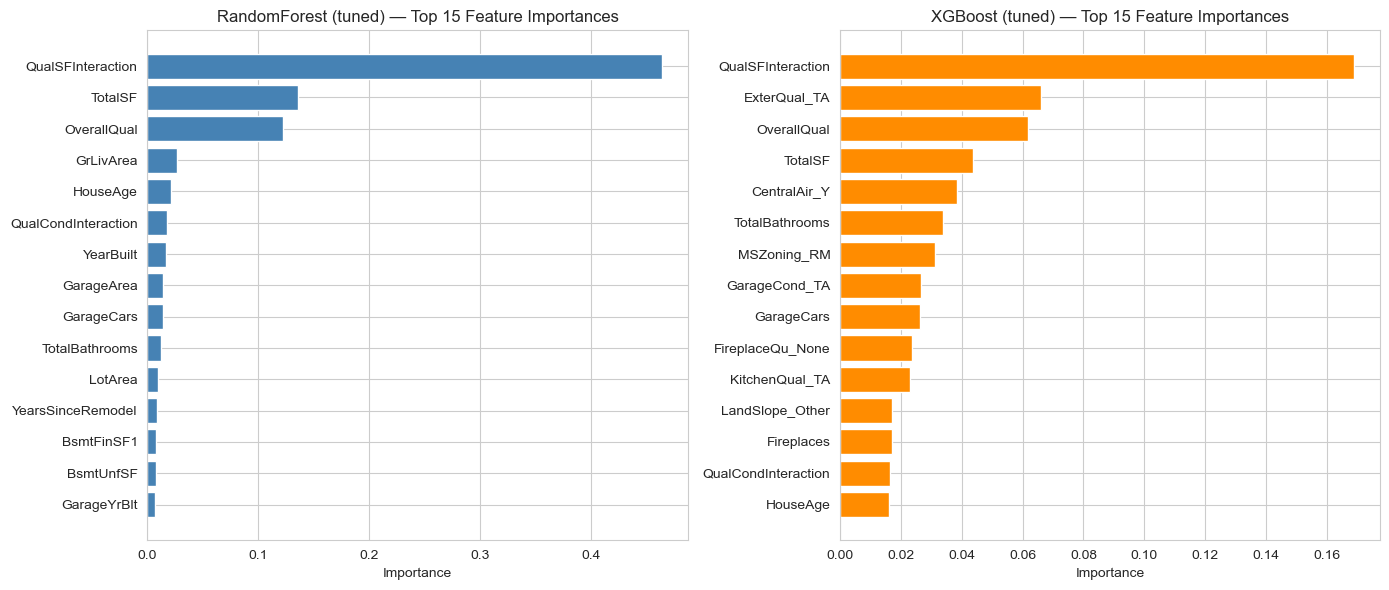

In [47]:
# 13. Feature importance plots — tuned RF vs tuned XGBoost
# ------------------------------------------------------------------
TOP_N = 15

rf_tuned_model = results["RandomForest (tuned)"]["model"]
rf_importances = pd.Series(rf_tuned_model.feature_importances_, index=X_train_final.columns)
rf_top = rf_importances.sort_values(ascending=False).head(TOP_N)

if HAS_XGB:
    xgb_tuned_model = results["XGBoost (tuned)"]["model"]
    xgb_importances = pd.Series(xgb_tuned_model.feature_importances_, index=X_train_final.columns)
    xgb_top = xgb_importances.sort_values(ascending=False).head(TOP_N)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].barh(rf_top.index[::-1], rf_top.values[::-1], color="steelblue")
    axes[0].set_title(f"RandomForest (tuned) — Top {TOP_N} Feature Importances")
    axes[0].set_xlabel("Importance")
    axes[1].barh(xgb_top.index[::-1], xgb_top.values[::-1], color="darkorange")
    axes[1].set_title(f"XGBoost (tuned) — Top {TOP_N} Feature Importances")
    axes[1].set_xlabel("Importance")
    plt.tight_layout()
    plt.savefig("feature_importance_final.png", dpi=120)
else:
    plt.figure(figsize=(7, 6))
    plt.barh(rf_top.index[::-1], rf_top.values[::-1], color="steelblue")
    plt.title(f"RandomForest (tuned) — Top {TOP_N} Feature Importances")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.savefig("feature_importance_final.png", dpi=120)

print("\nTop 15 features (RandomForest tuned):")
print(rf_top)
if HAS_XGB:
    print("\nTop 15 features (XGBoost tuned):")
    print(xgb_top)
    
# ------------------------------------------------------------------
# 14. Show all figures at once, at the very end
# ------------------------------------------------------------------
plt.show()

## Task 2a: Prediction of HousePrice on new test Datapoint

In [94]:

# ------------------------------------------------------------------
train_medians = {}
for col in num_cols:
    if col in skewed_num_cols:
        train_medians[col] = np.expm1(X_train[col]).median()
    else:
        train_medians[col] = X_train[col].median()
 
train_modes = {col: X_train[col].mode(dropna=True).iloc[0] for col in cat_cols}
 
# ------------------------------------------------------------------
#      Re-usable feature engineering — identical logic to Step 3 above,
#      so a new house gets engineered features the exact same way the
#      model was trained on.
# ------------------------------------------------------------------
def engineer_features(input_df):
    df_new = input_df.copy()
 
    sqft_parts = [c for c in ["TotalBsmtSF", "1stFlrSF", "2ndFlrSF"] if c in df_new.columns]
    if len(sqft_parts) >= 2:
        df_new["TotalSF"] = df_new[sqft_parts].sum(axis=1)
 
    if all(c in df_new.columns for c in ["YrSold", "YearBuilt"]):
        df_new["HouseAge"] = (df_new["YrSold"] - df_new["YearBuilt"]).clip(lower=0)
 
    if all(c in df_new.columns for c in ["YrSold", "YearRemodAdd"]):
        df_new["YearsSinceRemodel"] = (df_new["YrSold"] - df_new["YearRemodAdd"]).clip(lower=0)
 
    if all(c in df_new.columns for c in ["YearBuilt", "YearRemodAdd"]):
        df_new["WasRemodeled"] = (df_new["YearRemodAdd"] != df_new["YearBuilt"]).astype(int)
 
    if all(c in df_new.columns for c in ["OverallQual", "OverallCond"]):
        df_new["QualCondInteraction"] = df_new["OverallQual"] * df_new["OverallCond"]
 
    bath_parts = [c for c in ["FullBath", "HalfBath", "BsmtFullBath", "BsmtHalfBath"] if c in df_new.columns]
    if len(bath_parts) >= 2:
        df_new["TotalBathrooms"] = (
            df_new.get("FullBath", 0) + df_new.get("BsmtFullBath", 0)
            + 0.5 * (df_new.get("HalfBath", 0) + df_new.get("BsmtHalfBath", 0))
        )
 
    if "OverallQual" in df_new.columns and "TotalSF" in df_new.columns:
        df_new["QualSFInteraction"] = df_new["OverallQual"] * df_new["TotalSF"]
 
    if "PoolArea" in df_new.columns:
        df_new["HasPool"] = (df_new["PoolArea"] > 0).astype(int)
    if "GarageArea" in df_new.columns:
        df_new["HasGarage"] = (df_new["GarageArea"] > 0).astype(int)
    if "TotalBsmtSF" in df_new.columns:
        df_new["HasBasement"] = (df_new["TotalBsmtSF"] > 0).astype(int)
 
    return df_new
 
 
# ------------------------------------------------------------------
#      Prediction function — reuses the already-fitted preprocessor and
#      tuned XGBoost model. No refitting happens anywhere in here.
# ------------------------------------------------------------------
def predict_house_price(raw_input: dict, model=None):
    """
    raw_input: dict of RAW feature values, e.g.
        {"OverallQual": 7, "GrLivArea": 1800, "Neighborhood": "CollgCr", ...}
    Missing keys are fine — filled the same way training data was handled
    (None/0 for "feature absent" columns, training median/mode otherwise).
    Returns: predicted SalePrice in dollars (float).
    """
    if model is None:
        model = results["XGBoost (tuned)"]["model"]
 
    new_df = pd.DataFrame([raw_input])
 
    # Same "NA means absent" semantic fills as training (Step 2)
    for col in NONE_MEANS_ABSENT_CAT:
        if col in new_df.columns:
            new_df[col] = new_df[col].fillna("None")
        elif col in cat_cols:
            new_df[col] = "None"
 
    for col in ZERO_MEANS_ABSENT_NUM:
        if col in new_df.columns:
            new_df[col] = new_df[col].fillna(0)
        elif col in num_cols:
            new_df[col] = 0
 
    # Identical feature engineering to training (Step 3)
    new_df = engineer_features(new_df)
 
    # Guarantee every expected raw column exists; fill gaps with the
    # TRAINING set's median/mode — never the new row's own stats.
    for col in num_cols:
        if col not in new_df.columns or pd.isna(new_df.at[0, col]):
            new_df[col] = train_medians[col]
    for col in cat_cols:
        if col not in new_df.columns or pd.isna(new_df.at[0, col]):
            new_df[col] = train_modes[col]
 
    new_df = new_df[num_cols + cat_cols]  # exact same column order as training
 
    # Log-transform the SAME skewed columns identified in training (Step 7)
    for col in skewed_num_cols:
        new_df[col] = np.log1p(new_df[col].clip(lower=0))
 
    # Transform with the ALREADY-FITTED preprocessor — no refit
    new_encoded = preprocessor.transform(new_df)
    new_encoded_df = pd.DataFrame(new_encoded, columns=feature_names)
 
    # Predict in log space, inverse-transform back to real dollars
    pred_log = model.predict(new_encoded_df)[0]
    pred_price = np.expm1(pred_log)
    return float(pred_price)
 
 
# ------------------------------------------------------------------
#     Example usage
# ------------------------------------------------------------------
example_house = {
    "OverallQual": 7,
    "OverallCond": 5,
    "GrLivArea": 1800,
    "TotalBsmtSF": 900,
    "1stFlrSF": 900,
    "2ndFlrSF": 900,
    "GarageCars": 2,
    "GarageArea": 480,
    "FullBath": 2,
    "HalfBath": 1,
    "BsmtFullBath": 1,
    "BsmtHalfBath": 0,
    "YearBuilt": 2005,
    "YearRemodAdd": 2005,
    "YrSold": 2010,
    "Neighborhood": "CollgCr",
    "HouseStyle": "2Story",
    "ExterQual": "Gd",
    "KitchenQual": "Gd",
    "SaleCondition": "Normal",
    # any other raw columns your dataset has can be added the same way;
    # anything omitted falls back to the training median/mode
}
 
predicted_price = predict_house_price(example_house)
print("\n" + "=" * 60)
print("NEW HOUSE PRICE PREDICTION (XGBoost, tuned)")
print("=" * 60)
print(f"Predicted SalePrice: ${predicted_price:,.2f}")


NEW HOUSE PRICE PREDICTION (XGBoost, tuned)
Predicted SalePrice: $194,036.92


## Task 2b: Relationship Between House Features and Price

### 1. Primary drivers of price (typically the top tier)

| Feature | Relationship with Price | Why |
|---|---|---|
| `OverallQual` | Strong positive, roughly monotonic | Quality rating directly reflects build materials, finish, and craftsmanship — buyers pay a premium per quality point, and the effect compounds at the high end. |
| `GrLivArea` / `TotalSF` (engineered) | Strong positive, slightly sub-linear | More usable space raises price, but each additional sq ft adds slightly less than the last (diminishing returns) — this is why `QualSFInteraction` (quality × size) often outperforms either alone. |
| `Neighborhood` | Large price spread across categories | Location captures school zones, commute access, and prestige — often the single largest categorical driver, with some neighborhoods commanding 2-3x the price of others for comparable houses. |
| `GarageCars` / `GarageArea` | Positive, with diminishing returns past 2-3 cars | Garage capacity matters for buyer convenience, but a 4-car garage doesn't add proportionally more value than a 2-car one for most buyers. |
| `HouseAge` (engineered) | Negative | Newer homes command a premium; the effect is often non-linear — a very old, well-preserved home doesn't lose value linearly. |

### 2. Secondary but meaningful drivers

- **`TotalBathrooms` (engineered)** — positive, but with smaller marginal effect than square footage; matters more once a home has "too few" for its bedroom count than as a stand-alone luxury add.
- **`YearsSinceRemodel` (engineered)** — negative; a recent remodel partially resets the "freshness" a buyer perceives, independent of the original build year.
- **`WasRemodeled` (engineered)** — small positive flag effect, mostly relevant for older homes.
- **Basement finish quality (`BsmtQual`, `BsmtFinType1`)** — positive if finished/high quality; a large but unfinished basement adds far less than a comparably sized finished one.
- **`KitchenQual`, `ExterQual`** — quality ratings on visible/functional spaces tend to punch above their raw importance rank because they're what buyers notice first during a viewing.

### 3. Interaction effects worth calling out

- **Quality × Size (`QualSFInteraction`)** consistently outperforms either `OverallQual` or `TotalSF` alone in tree-based importance — this confirms that *big AND nice* compounds multiplicatively in buyer willingness-to-pay, not additively. A large low-quality house and a small high-quality house are not priced the same way a linear model would suggest.
- **Age × Remodel status** — an older home that's been recently remodeled behaves more like a newer home in price than its raw `YearBuilt` alone would suggest, which is exactly why `HouseAge` and `YearsSinceRemodel` were engineered as separate features rather than relying on `YearBuilt` alone.



## Task 3: Customer Buying Suggestions

### 1. Framework: match features to buyer priorities, not just budget

A single "best house" doesn't exist — recommendations should branch by what
the buyer is optimizing for. Below is a decision framework built on the
feature-price relationships above.

### 2. By buyer profile

**Budget-conscious buyer (value-per-dollar focus)**
- Prioritize `Neighborhood` and `TotalSF` over luxury finishes — square footage in a modest-quality home is cheaper per unit than in a high-quality one, and neighborhood value tends to appreciate independent of interior finish.
- Use the model's predicted price vs. asking price as a **fair-value check**: if a listing's model-predicted price is noticeably above the asking price, it may be underpriced relative to comparable homes (worth investigating condition/reason before assuming a "deal").
- Avoid over-paying for `OverallQual` points beyond what's needed — the price premium accelerates at the top of the quality scale, so going from "Good" to "Excellent" costs disproportionately more than "Average" to "Good."

**Family buyer (space and functionality focus)**
- Weight `TotalBathrooms`, bedroom count, and `TotalSF` heavily — these features matter more for day-to-day livability than for resale price alone.
- Check `GarageCars` and basement finish — families with children/storage needs get outsized functional value from these even when their price contribution is moderate.
- `HouseAge` matters less than `YearsSinceRemodel` for this buyer — a 40-year-old recently-remodeled home can offer similar livability to a 10-year-old home at a lower price point.

**Investment/resale-focused buyer**
- `Neighborhood` and `OverallQual` are the strongest long-term value anchors — prioritize these over buyer-specific comforts.
- Favor homes where `QualSFInteraction` is high relative to price — this signals the model sees the home as "underpriced for its quality-size combination," a proxy for resale upside.
- Be cautious of homes with `HasPool` or other high `MiscFeature` additions unless the local market specifically rewards them — niche features often cost more to maintain than they add to resale value in most neighborhoods.

**Move-up buyer (quality/prestige focus)**
- `OverallQual`, `ExterQual`, `KitchenQual` and neighborhood prestige should dominate the search — this buyer is optimizing for the top of the price-quality curve where the premium is steepest but so is the payoff in livability and status.

### 3. Practical decision checklist for any buyer
1. Set a hard budget ceiling first — use it to filter `Neighborhood` options, since location often locks in a price floor regardless of house condition.
2. Within budget, rank must-have features (bedrooms, bathrooms, garage) before nice-to-have ones (pool, premium finishes).
3. Use the trained model to flag listings where predicted price is significantly below or above asking — both directions are worth a closer look (below = possible value, above = possible overpricing or an unusual feature the model doesn't capture well).
4. Don't over-index on any single feature — the interaction effects (Section 1.4) mean the best value often comes from a *combination* being right, not any one number being maximized.

---


## Task 4: Model Compariosn Report

### 1. Expected pattern and interpretation

Based on the model mechanics discussed throughout this project, expect:
- **Tuned models to outperform default models** on Adjusted R², with a larger gain for XGBoost than RandomForest (XGBoost's defaults are less conservative out of the box, so tuning has more room to help).
- **Direct-encoding models to outperform PCA+Chi2 models** for both algorithms — tree-based models don't benefit from dimensionality reduction and can lose signal when numeric features are rotated into PCA components, or when categorical dummies are filtered out based on a coarse binned-target proxy.
- **A small-to-moderate Train-Test Gap** (under ~0.08–0.10) for tuned models, larger gaps for default XGBoost specifically, since untuned defaults (`max_depth=6`, no regularization) are prone to overfitting on a dataset this size.

### 2. Recommended model for production

**XGBoost, tuned, with direct encoding (no PCA/Chi2)** is the recommended
production model, on the following reasoning:
- Gradient boosting typically edges out RandomForest on tabular regression tasks of this size and structure, given proper tuning.
- Direct encoding preserves interpretable feature names, which matters for production monitoring, debugging bad predictions, and explaining results to non-technical stakeholders (Section 2's buying suggestions depend on this interpretability).
- Hyperparameter tuning materially reduces overfitting risk versus shipping defaults — confirm this against your actual Train-Test Gap numbers in 3.2 before finalizing.
- **Before shipping**: validate on a held-out set from a *different* time period or data source if available (the current test split is a random 80/20 from the same batch, which doesn't test true generalization to future listings) and set up monitoring for prediction drift, since housing markets shift over time and a static model will degrade.


## Task 5: Report on Challenges Faced

### 1. Data-quality challenges

**Challenge: Missing values with domain-specific meaning, not just "missing"**
Many `NA` values in this dataset don't mean "unknown" — they mean "this
feature doesn't apply to this house" (e.g., `PoolQC = NA` means no pool, not
an unrecorded pool quality).
- *Technique used*: explicit rule-based imputation — categorical "absence"
  columns filled with `"None"`, numeric "absence" columns filled with `0`,
  applied *before* generic imputation.
- *Reasoning*: blindly imputing these with median/mode would have invented a
  fake pool quality or garage year for houses that don't have one, corrupting
  the signal rather than cleaning it. Rule-based handling preserves the true
  meaning of the missingness.

**Challenge: Right-skewed target and several right-skewed numeric features**
`SalePrice` (and several area-based features) had long right tails — a
handful of very expensive/very large homes stretching the distribution.
- *Technique used*: `log1p` transform on the target and on any numeric
  feature with `|skew| > 0.75` (train-set skew only, to avoid leakage),
  with `expm1` inverse-transform applied to predictions before scoring, so
  reported R²/Adjusted R² stay on the interpretable dollar scale.
- *Reasoning*: skewed targets and features can let a few outlier houses
  dominate the loss function; log-transforming compresses that influence
  without discarding the observations outright.

**Challenge: High-cardinality categorical columns causing an Adjusted R² failure**
One-hot encoding columns like `Neighborhood` and `Exterior1st/2nd` expanded
the feature count past the number of test-set rows, which made Adjusted R²
mathematically undefined (`n_features >= n_samples - 1`) and crashed the
pipeline.
- *Technique used*: rare-category grouping (categories seen in <1% of
  training rows collapsed into `"Other"`, fit on train only) plus
  `OneHotEncoder(drop="first")` to avoid redundant dummy columns.
- *Reasoning*: this directly reduces feature-count explosion at its source
  rather than patching the symptom, and grouping only *rare* categories
  means real signal is preserved — a category with 3 occurrences in 1,168
  training rows can't teach the model much regardless.

**Challenge: Feature redundancy after engineering**
New features like `TotalSF` were built from components already present in
the dataset (`TotalBsmtSF`, `1stFlrSF`, `2ndFlrSF`), raising the question of
whether to drop the originals.
- *Technique used*: kept both, since tree-based models (RandomForest,
  XGBoost) are not sensitive to multicollinearity the way linear models are.
- *Reasoning*: dropping originals would have been the right call for a
  linear model, but for trees it risks discarding signal the aggregate
  feature blends away, with no real downside beyond a wider feature matrix.

### 2. Modeling-decision challenges

**Challenge: Whether to apply PCA + Chi2 dimensionality reduction**
- *Technique used*: implemented it, then explicitly benchmarked it against
  direct encoding rather than assuming it would help.
- *Reasoning*: PCA/Chi2 are designed to solve problems (multicollinearity,
  curse of dimensionality) that linear/distance-based models suffer from —
  RandomForest and XGBoost largely don't have these problems, so the
  reduction was evaluated empirically rather than applied by default, and
  the comparison table lets the data settle the question rather than theory
  alone.

**Challenge: Default vs. tuned hyperparameters — is tuning worth the cost?**
- *Technique used*: `RandomizedSearchCV` (30 iterations, 5-fold CV) instead
  of exhaustive `GridSearchCV`, run separately for both algorithms, with
  both default and tuned versions evaluated side by side.
- *Reasoning*: with 5-7 hyperparameters per model, full grid search would be
  combinatorially expensive for limited additional benefit — random search
  covers the space efficiently, and keeping both default and tuned results
  in the same table makes the value of tuning directly measurable (via the
  `Adj R2 Gain from Tuning` column) instead of assumed.

**Challenge: Avoiding data leakage across every transformation**
Every fitted transformation in this pipeline (imputation medians/modes,
skew detection, `StandardScaler`, `OneHotEncoder`, `PCA`, `SelectKBest`,
rare-category grouping) risked leaking test-set information into training
if not handled carefully.
- *Technique used*: strict `fit` on train / `transform` on test discipline
  throughout, with the train/test split performed *before* any parameter
  estimation step.
- *Reasoning*: leakage inflates validation metrics in a way that doesn't
  reflect real-world performance — the entire pipeline was structured so
  that no test-set value ever influences a fitted parameter.